# Atelier : détection d’anomalies avec Python

Notebook principal du TP. Les fonctions réutilisables sont regroupées dans `utils.py`.

## Protocole commun et mesures

### 1. Séparer apprentissage et évaluation

Pour Credit Card et AI4I, je sépare les données en **60 % d’apprentissage, 20 % de validation et 20 % de test**. Le découpage est stratifié et reproductible (graine 42). Il est créé une seule fois pour chaque jeu, puis réutilisé pour toutes les méthodes.

| Partition | Utilisation |
|---|---|
| Apprentissage | Ajuster les transformations et entraîner les modèles ; appliquer SMOTE pour les variantes concernées |
| Validation | Choisir les hyperparamètres, le seuil et la méthode |
| Test | Évaluer les choix figés, sans les modifier selon les résultats obtenus |

Les transformations ajustables sont apprises sur l’apprentissage seulement. Le rééchantillonnage est placé dans le pipeline : **ni la validation ni le test ne sont rééquilibrés**. La validation croisée n’est pas utilisée ; elle n’est pas exigée ici.

Ce découpage aléatoire sert de cadre commun de comparaison. Il mélange passé et futur : pour une utilisation prospective, il faudrait également étudier un découpage temporel.

La recherche reste limitée :

| Jeu et famille | Configurations comparées | Effectif d’apprentissage avant SMOTE éventuel |
|---|---:|---:|
| Credit Card — arbre de décision | 6 : deux profondeurs × trois traitements du déséquilibre | 165 397 |
| Credit Card — régression logistique | 6 : deux valeurs de C × trois traitements du déséquilibre | 165 397 |
| Credit Card — Isolation Forest | 4 | 165 397 |
| Credit Card — LOF | 4 nombres de voisins | 30 000 |
| Credit Card — HBOS | 3 nombres de cases | 165 397 |
| AI4I — logistique et Isolation Forest | 1 configuration chacun, reprise de Credit Card | 6 000 chacun |

LOF utilise un **sous-échantillon stratifié fixe de 30 000 transactions**, contenant 52 fraudes. Il est partagé entre ses quatre configurations ; validation et test restent complets. Les autres méthodes utilisent l’apprentissage complet. Le contrôle indicatif d’un arbre sur la validation AI4I est présenté séparément, sans changer la sélection.

**Où est-ce appliqué ?** `utils.decouper_donnees` effectue le découpage avec deux appels stratifiés à `train_test_split`. Les partitions sont affichées dans « Préparer Credit Card » et « Chargement, cible et prétraitement » pour AI4I. `utils.sous_echantillon_stratifie` construit le sous-échantillon LOF. Les pipelines et les configurations sont définis dans « Configurations comparées ».

### 2. Deux niveaux d’évaluation

La classe d’intérêt vaut **1** : anomalie pour Mouse, fraude pour Credit Card et panne pour AI4I. Tous les scores suivent la convention **élevé = suspect**. `utils.score_anomalie` inverse les scores sklearn d’IF et de LOF ; pour les classifieurs, il utilise la probabilité prédite de la classe 1.

| Niveau | Indicateurs | Ce qui est évalué |
|---|---|---|
| Classement, sans seuil choisi | Courbes ROC et précision-rappel, AUC-ROC, **Average Precision (AP)** | L’ordre des observations selon leurs scores continus |
| Décisions, avec seuil figé | Matrice de confusion, précision, rappel, F1 positif, balanced accuracy, nombres d’alertes, de faux positifs et de faux négatifs | Les alertes effectivement produites |

L’**AP est la mesure principale de classement**, calculée par `average_precision_score(y, scores)`, et non une aire PR par trapèzes. Le F1 combine précision et rappel de la classe positive. La balanced accuracy est la moyenne des rappels des deux classes : une bonne valeur ne garantit pas que les alertes sont fiables.

**Où est-ce appliqué ?** `utils.evaluer` calcule AP et AUC-ROC ; `utils.tracer_courbes` produit les deux courbes. `utils.rapport_seuil` calcule la matrice et les mesures après seuillage. Les matrices et tableaux de test sont affichés par `tableau_test`, dans les parties 2, 3 et 4. Les résultats Mouse sont présentés dans la partie 1.

### 3. Objectifs opérationnels imposés

| Application | Contrainte sur la validation | Objectif |
|---|---|---|
| Fraude | **Précision ≥ 80 %** | Retrouver le plus de fraudes possible en limitant les enquêtes inutiles |
| Maintenance | **Précision ≥ 90 %** | Retrouver le plus de pannes possible avec des alertes suffisamment fiables pour déclencher une intervention |

Pour chaque configuration, je cherche le seuil qui donne le **meilleur rappel sous la contrainte de précision**, avec **au moins une alerte**. En cas d’égalité, je privilégie la précision, puis l’AP pour départager les configurations. Les tableaux indiquent le nombre d’alertes : une précision élevée sur deux cas seulement reste fragile. Ces valeurs sont les contraintes pédagogiques du TP, pas des normes universelles.

Si aucune configuration d’une famille ne satisfait la contrainte, je signale **« objectif non atteint »**, sans abaisser l’exigence. Le compromis choisi dans ce TP maximise alors le F1 de validation, à la fois pour le seuil et pour la configuration.

Le modèle et son seuil sont ensuite figés avant le test. Je rapporte la précision et le rappel du test **même si la contrainte n’y est plus respectée**, sans ajuster le seuil après coup. Les évaluations utilisent `score >= seuil` ; la décision native par défaut des détecteurs sklearn utilise une frontière stricte, distinction précisée dans la partie Mouse.

**Où est-ce appliqué ?** Les constantes `PRECISION_MIN_FRAUDE = 0.80` et `PRECISION_MIN_PANNE = 0.90` sont définies dans les parties 2 et 4. `utils.choisir_seuil_contraint` choisit le seuil sur la validation. `utils.comparer_configurations` rassemble les résultats et `utils.selectionner` classe les configurations. Les sections « Évaluation finale sur le test » et « Seuil sous précision ≥ 90 % (validation), puis test » appliquent les choix retenus.

Les versions sont affichées ci-dessous. Les temps d’apprentissage et de calcul des scores sont mesurés séparément, et les avertissements ne sont pas masqués.


In [1]:
import platform
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import imblearn
import shap

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

import utils
from utils import (
    score_anomalie, seuil_defaut, entrainer_et_scorer, evaluer, rapport_seuil,
    seuil_iqr, seuil_kmeans, choisir_seuil_contraint, selectionner,
    tracer_courbes, tracer_metriques_seuil,
)

from utils import arrondir
GRAINE = 42
np.random.seed(GRAINE)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)





print("Python      ", platform.python_version())
for module in (np, pd, matplotlib, sns, sklearn, imblearn, shap):
    print(f"{module.__name__:<12}", module.__version__)

Python       3.14.3
numpy        2.5.4
pandas       3.1.0
matplotlib   3.11.2
seaborn      0.13.2
sklearn      1.9.1
imblearn     0.14.2
shap         0.54.1


---
## Partie 1 : Données Mouse
### 1.a Chargement et observation
Le fichier utilise des fins de ligne `\r`. Les étiquettes (10 dernières lignes = anomalies) sont construites
**avant** tout mélange et ne servent qu'à l'évaluation.

(500, 2) | anomalies : 10
{'x1': dtype('float64'), 'x2': dtype('float64')} | valeurs manquantes : 0


,count,mean,std,min,25%,50%,75%,max
x1,500.0,0.505892,0.191763,0.040555,0.328481,0.504702,0.681430,0.916030
x2,500.0,0.599706,0.156863,0.138940,0.469010,0.629494,0.735364,0.897028


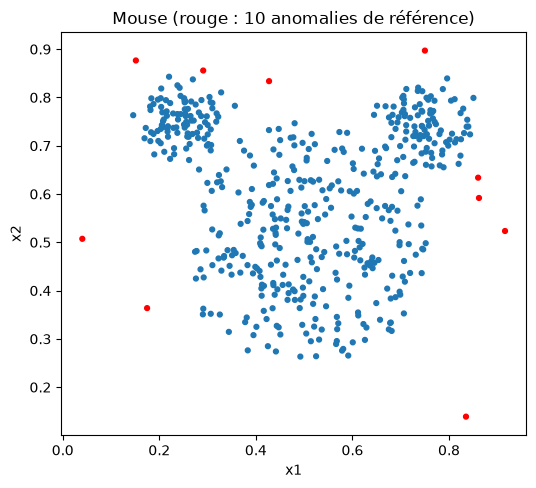

In [2]:
X_mouse, y_mouse = utils.charger_mouse("data/mouse.txt")
print(X_mouse.shape, "| anomalies :", y_mouse.sum())
print(X_mouse.dtypes.to_dict(), "| valeurs manquantes :", X_mouse.isna().sum().sum())
display(X_mouse.describe().T)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(X_mouse.x1, X_mouse.x2, c=np.where(y_mouse == 1, "red", "tab:blue"), s=12)
ax.set(title="Mouse (rouge : 10 anomalies de référence)", xlabel="x1", ylabel="x2", aspect="equal")
plt.show()

Trois nuages (tête et deux oreilles) de densités différentes, et 10 points dispersés autour.

### 1.b Isolation Forest et LOF (détection d'outliers)
Les deux méthodes sont ajustées sur l'ensemble Mouse **sans les étiquettes**, avec leurs paramètres par défaut
(IF : 100 arbres, `max_samples=256`, `contamination="auto"` ; LOF : `n_neighbors=20`, `contamination="auto"`).
Les deux variables ont la même échelle : aucune standardisation n'est nécessaire.

Isolation Forest  apprentissage : 0.0594 s | score : 0.0051 s | seuil : 0.500
LOF               apprentissage : 0.0025 s | score : 0.0000 s | seuil : 1.500


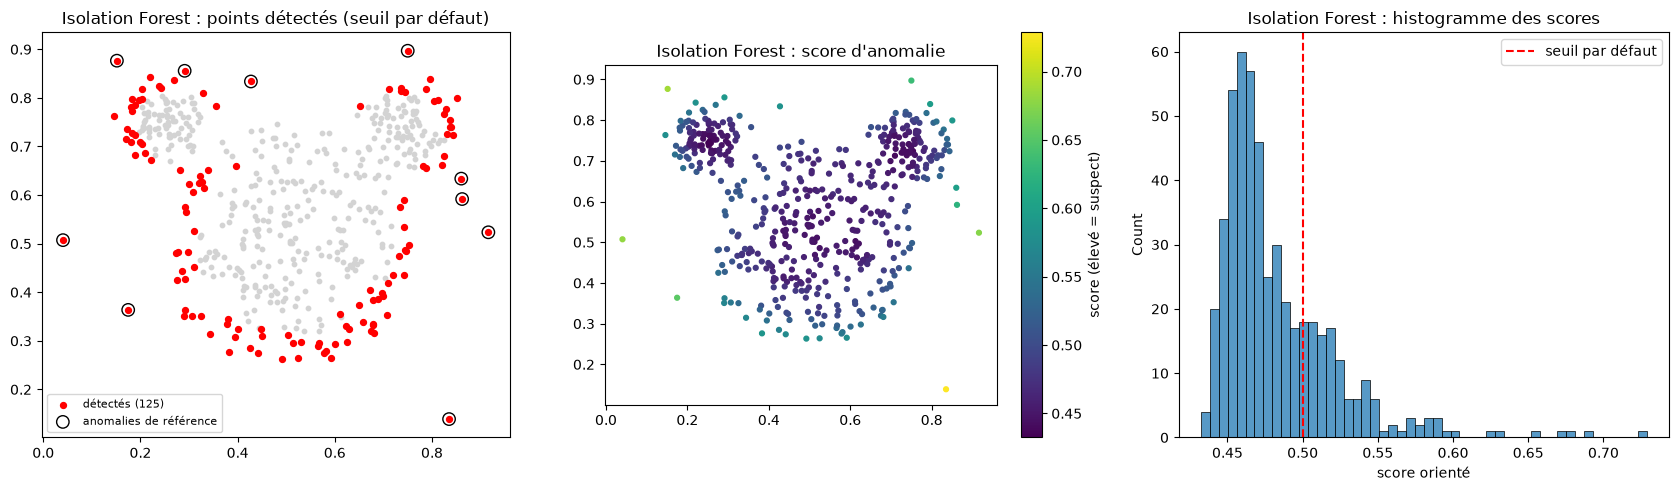

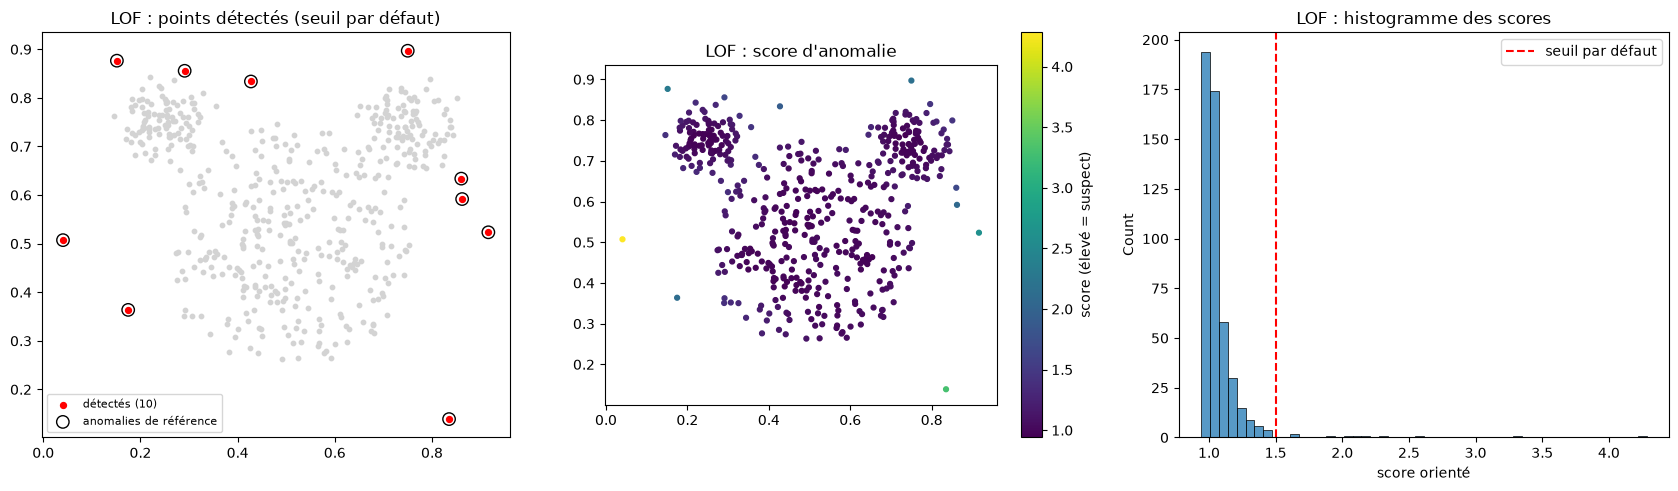

In [3]:
modeles_mouse = {
    "Isolation Forest": IsolationForest(random_state=GRAINE),
    "LOF": LocalOutlierFactor(n_neighbors=20),
}
scores_mouse, defaut_mouse = {}, {}
for nom, modele in modeles_mouse.items():
    debut = time.perf_counter()
    modele.fit(X_mouse)
    temps_app = time.perf_counter() - debut
    debut = time.perf_counter()
    scores_mouse[nom] = score_anomalie(modele, X_mouse)
    temps_score = time.perf_counter() - debut
    defaut_mouse[nom] = seuil_defaut(modele)
    print(f"{nom:<17} apprentissage : {temps_app:.4f} s | score : {temps_score:.4f} s | seuil : {defaut_mouse[nom]:.3f}")


def tracer_mouse(scores, seuil, nom):
    """
    Rôles : Afficher points détectés, couleur par score et histogramme des scores (Mouse).
    Saisies :
        - scores : scores orientés
        - seuil : seuil de décision
        - nom : nom de la méthode
    Résultat : aucun (affiche la figure)
    """
    detectes = scores >= seuil
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    axes[0].scatter(X_mouse.x1, X_mouse.x2, c="lightgrey", s=10)
    axes[0].scatter(X_mouse.x1[detectes], X_mouse.x2[detectes], c="red", s=18, label=f"détectés ({detectes.sum()})")
    axes[0].scatter(X_mouse.x1[y_mouse == 1], X_mouse.x2[y_mouse == 1], facecolors="none", edgecolors="k",
                    s=80, label="anomalies de référence")
    axes[0].set(title=f"{nom} : points détectés (seuil par défaut)", aspect="equal")
    axes[0].legend(fontsize=8)
    points = axes[1].scatter(X_mouse.x1, X_mouse.x2, c=scores, cmap="viridis", s=12)
    fig.colorbar(points, ax=axes[1], label="score (élevé = suspect)")
    axes[1].set(title=f"{nom} : score d'anomalie", aspect="equal")
    sns.histplot(scores, bins=50, ax=axes[2])
    axes[2].axvline(seuil, color="red", linestyle="--", label="seuil par défaut")
    axes[2].set(title=f"{nom} : histogramme des scores", xlabel="score orienté")
    axes[2].legend()
    plt.tight_layout()
    plt.show()


for nom in modeles_mouse:
    tracer_mouse(scores_mouse[nom], defaut_mouse[nom], nom)

**Deux scores LOF différents.** Avec `novelty=False`, le score des points d'apprentissage est
`negative_outlier_factor_` : chaque point est comparé à ses k voisins **autres que lui-même**.
Avec `novelty=True`, `score_samples` est prévu pour de **nouvelles** observations : appliqué aux points
d'apprentissage, chaque point se retrouverait parmi ses propres voisins (distance 0), ce qui gonfle sa densité
locale et écrase son score. C'est pourquoi on n'utilise pas ce mode pour réévaluer l'apprentissage.

In [4]:
lof_nouveaute = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(X_mouse)
comparaison = pd.DataFrame({
    "LOF outlier (-negative_outlier_factor_)": -lof_nouveaute.negative_outlier_factor_,
    "LOF novelty appliqué à tort (-score_samples)": -lof_nouveaute.score_samples(X_mouse),
    "anomalie": y_mouse,
})
display(comparaison.groupby("anomalie").mean().round(3))
print("AP outlier :", round(evaluer(y_mouse, comparaison.iloc[:, 0])["ap"], 3),
      "| AP novelty sur l'apprentissage :", round(evaluer(y_mouse, comparaison.iloc[:, 1])["ap"], 3))

/Users/max/Documents/Ecole/M2/Machine Learning/TP1/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


,LOF outlier (-negative_outlier_factor_),LOF novelty appliqué à tort (-score_samples)
anomalie,,
0,1.050,1.042
1,2.407,2.322


AP outlier : 1.0 | AP novelty sur l'apprentissage : 1.0


Les scores obtenus « à tort » sont en moyenne plus faibles (le point lui-même entre dans son voisinage, à distance 0).
Avec k = 20 l'effet reste modeste et le classement ne change presque pas ; il serait bien plus marqué avec un petit k.
La distance nulle ne donne pas une densité infinie : LOF utilise la distance d'atteignabilité
`max(distance(x, voisin), k-distance(voisin))`, puis l'inverse de sa moyenne (avec stabilisation numérique).

### 1.c Choisir un seuil sans étiquettes
Deux heuristiques, appliquées aux scores orientés et **sans consulter les étiquettes** :
- **IQR** : seuil = Q3 + 1,5 × (Q3 − Q1), règle de la boîte à moustaches. Paramètre 1,5 fixé a priori.
- **Clustering** : KMeans à deux groupes sur les scores (1D) ; le groupe au centre le plus élevé est déclaré anomalie.

sklearn déclare une anomalie si `decision_function < 0`, soit score orienté **strictement >** `-offset_`.
L'évaluation utilise partout `score >= seuil` : seule une égalité exacte peut changer la décision.
Cette différence n'a pas d'effet sur les données actuelles.
Le F1 de la classe anomalie est la mesure principale.

,méthode,règle,seuil,alertes,VP,FP,FN,VN,précision,rappel,F1
0,Isolation Forest,défaut,0.500,125,10,115,0,375,0.080,1.0,0.148
1,Isolation Forest,IQR,0.563,21,10,11,0,479,0.476,1.0,0.645
2,Isolation Forest,KMeans,0.503,115,10,105,0,385,0.087,1.0,0.160
3,LOF,défaut,1.500,10,10,0,0,490,1.000,1.0,1.000
4,LOF,IQR,1.226,37,10,27,0,463,0.270,1.0,0.426
5,LOF,KMeans,1.915,8,8,0,2,490,1.000,0.8,0.889


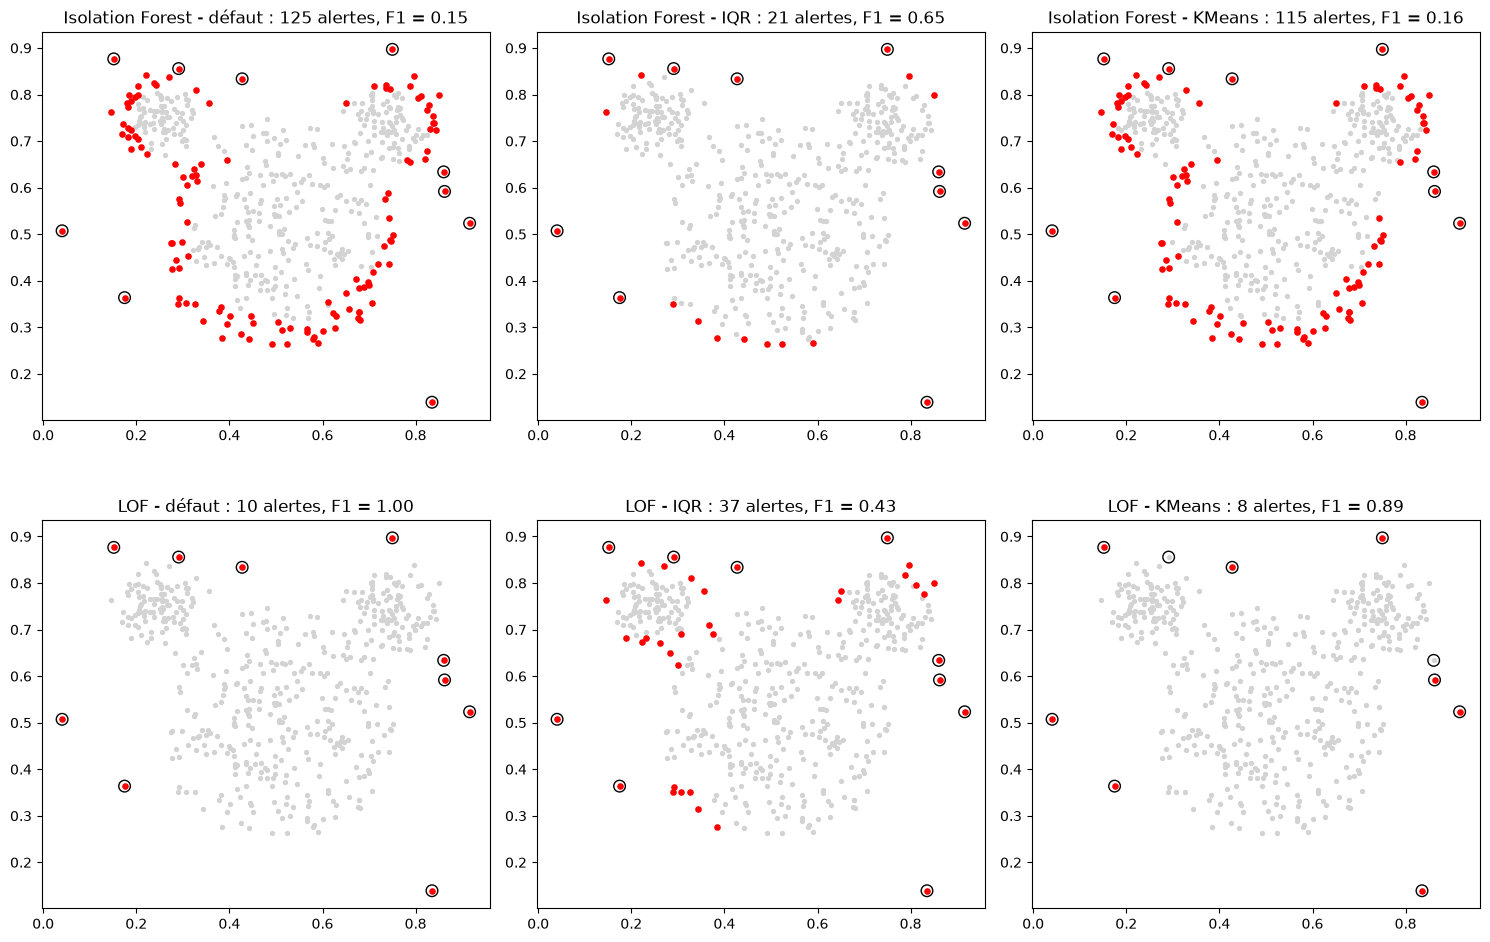

In [5]:
lignes, detections = [], {}
for nom in modeles_mouse:
    s = scores_mouse[nom]
    for regle, seuil in [("défaut", defaut_mouse[nom]), ("IQR", seuil_iqr(s)), ("KMeans", seuil_kmeans(s))]:
        r = rapport_seuil(y_mouse, s, seuil)
        detections[(nom, regle)] = s >= seuil
        (vn, fp), (fn, vp) = r["matrice"]
        lignes.append({"méthode": nom, "règle": regle, "seuil": seuil, "alertes": r["alertes"],
                       "VP": vp, "FP": fp, "FN": fn, "VN": vn, "précision": r["precision"],
                       "rappel": r["rappel"], "F1": r["f1"]})
tableau_seuils_mouse = pd.DataFrame(lignes)
display(tableau_seuils_mouse.round(3))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, ((nom, regle), detectes) in zip(axes.ravel(), detections.items()):
    ax.scatter(X_mouse.x1, X_mouse.x2, c="lightgrey", s=8)
    ax.scatter(X_mouse.x1[detectes], X_mouse.x2[detectes], c="red", s=14)
    ax.scatter(X_mouse.x1[y_mouse == 1], X_mouse.x2[y_mouse == 1], facecolors="none", edgecolors="k", s=70)
    f1 = tableau_seuils_mouse.query("méthode == @nom and règle == @regle")["F1"].iloc[0]
    ax.set(title=f"{nom} - {regle} : {detectes.sum()} alertes, F1 = {f1:.2f}", aspect="equal")
plt.tight_layout()
plt.show()

### 1.c (suite) Évaluation du classement : AP et AUC-ROC

,ap,auc_roc
Isolation Forest,0.9614,0.999
LOF,1.0000,1.000


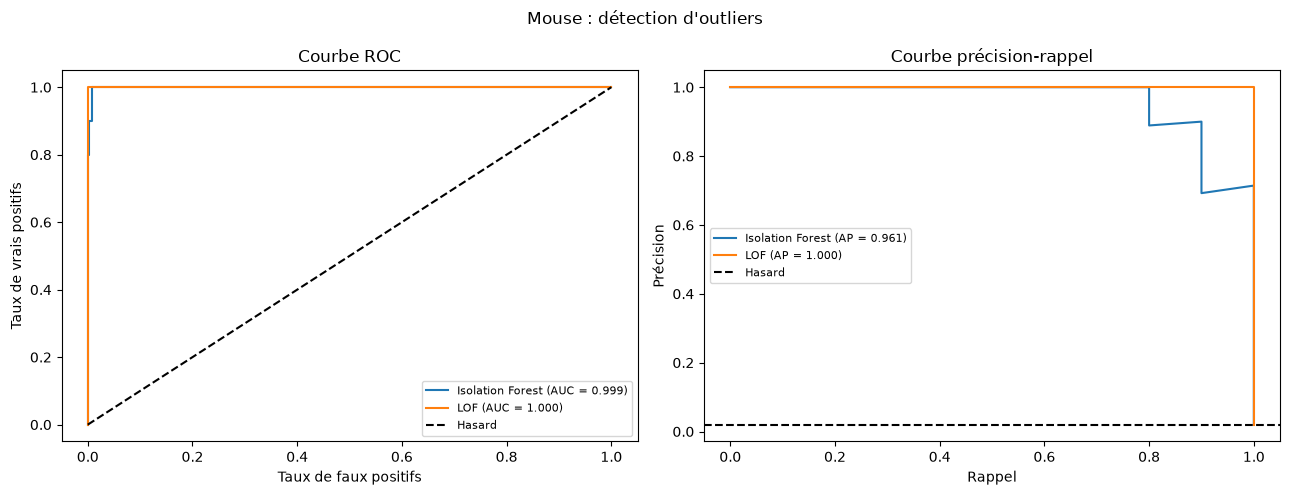

Signalés par IF seul : 4 | par LOF seul : 20 | par les deux : 17
Rang des 10 anomalies (1 = plus suspect) :


,490,491,492,493,494,495,496,497,498,499
Isolation Forest,10,6,3,1,5,2,8,7,4,14
LOF,10,5,1,2,6,4,9,7,3,8


In [6]:
display(pd.DataFrame({nom: evaluer(y_mouse, s) for nom, s in scores_mouse.items()}).T.round(4))
fig = tracer_courbes(y_mouse, scores_mouse, "Mouse : détection d'outliers")
plt.show()

# Désaccords entre IF et LOF au seuil IQR
d_if, d_lof = detections[("Isolation Forest", "IQR")], detections[("LOF", "IQR")]
print("Signalés par IF seul :", (d_if & ~d_lof).sum(), "| par LOF seul :", (~d_if & d_lof).sum(),
      "| par les deux :", (d_if & d_lof).sum())
rang = pd.DataFrame({nom: pd.Series(s).rank(ascending=False) for nom, s in scores_mouse.items()})
print("Rang des 10 anomalies (1 = plus suspect) :")
display(rang[y_mouse == 1].astype(int).T)

**Analyse des règles de seuil (Mouse).**
- *Isolation Forest* : le seuil par défaut (`contamination="auto"`, score original 0,5) signale 125 points, dont
  115 normaux : il est bien trop permissif ici. Les scores IF ne sont pas bimodaux, donc le KMeans coupe aussi au
  milieu de la masse (115 alertes). La règle IQR, qui ne retient que la queue de distribution, est la meilleure (F1 ≈ 0,65).
- *LOF* : le seuil par défaut (LOF > 1,5) retrouve exactement les 10 anomalies (F1 = 1). Les scores LOF des points
  normaux sont très concentrés autour de 1, donc l'IQR est étroit et la règle IQR devient trop permissive (37 alertes).
  Le KMeans isole un groupe de scores très élevés mais rate 2 anomalies (F1 ≈ 0,89).
- Aucune heuristique ne domine : la meilleure règle dépend de la forme de la distribution des scores, ce que
  confirment les histogrammes. Ces seuils sont des heuristiques, sans garantie.

**Pourquoi l'AP et l'AUC-ROC ne dépendent pas du seuil.** Les deux mesures sont calculées en parcourant *tous* les
seuils possibles : elles ne dépendent que de l'**ordre** des scores (une transformation croissante des scores ne
les modifie pas). Choisir un seuil revient à choisir un point de la courbe ROC ou PR, pas à changer la courbe.

**Désaccords IF / LOF.** IF isole par des coupures parallèles aux axes : il est sensible à l'isolement *global* et
donne des scores assez élevés aux points du bord extérieur des nuages. LOF compare la densité d'un point à celle
de ses voisins : un point en bordure d'une oreille dense reste « normal » s'il est aussi dense que ses voisins,
tandis qu'un point juste à l'extérieur d'un nuage dense est très suspect. Au seuil IQR, LOF signale 20 points que IF
ne signale pas (bords des nuages, où la densité chute), IF en signale 4 que LOF ne signale pas.
Les deux méthodes classent les 10 anomalies aux 14 premiers rangs : le classement est presque parfait, c'est la
**décision** qui diffère.

**Fragilité.** Avec 10 anomalies seulement, une anomalie manquée fait perdre 0,1 de rappel, et quelques points
normaux signalés font chuter la précision : le F1 varie par sauts. Ces résultats décrivent la détection *dans
l'échantillon observé* (les mêmes points servent à l'ajustement et à l'évaluation) ; ils n'estiment pas la
performance sur des données futures.

### 1.3 Passer à la détection de nouveautés
On réserve 30 % des points normaux **et toutes les anomalies** pour un test distinct. LOF (`novelty=True`,
`n_neighbors=20`) est ajusté sur les seuls points normaux restants, puis il score uniquement les points réservés.
Seuils : le seuil par défaut de LOF et la règle IQR calculée sur les scores LOF d'apprentissage
(`negative_outlier_factor_`), donc sans consulter le test.

apprentissage : 343 normaux | test : 157 points dont 10 anomalies
temps apprentissage : 0.0016 s | temps score : 0.0007 s


/Users/max/Documents/Ecole/M2/Machine Learning/TP1/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


,règle,seuil,alertes,FP,FN,précision,rappel,F1
0,défaut,1.500,11,2,1,0.818,0.9,0.857
1,IQR (apprentissage),1.232,23,13,0,0.435,1.0,0.606


Classement sur le test : {'ap': 0.977, 'auc_roc': 0.998}


/Users/max/Documents/Ecole/M2/Machine Learning/TP1/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


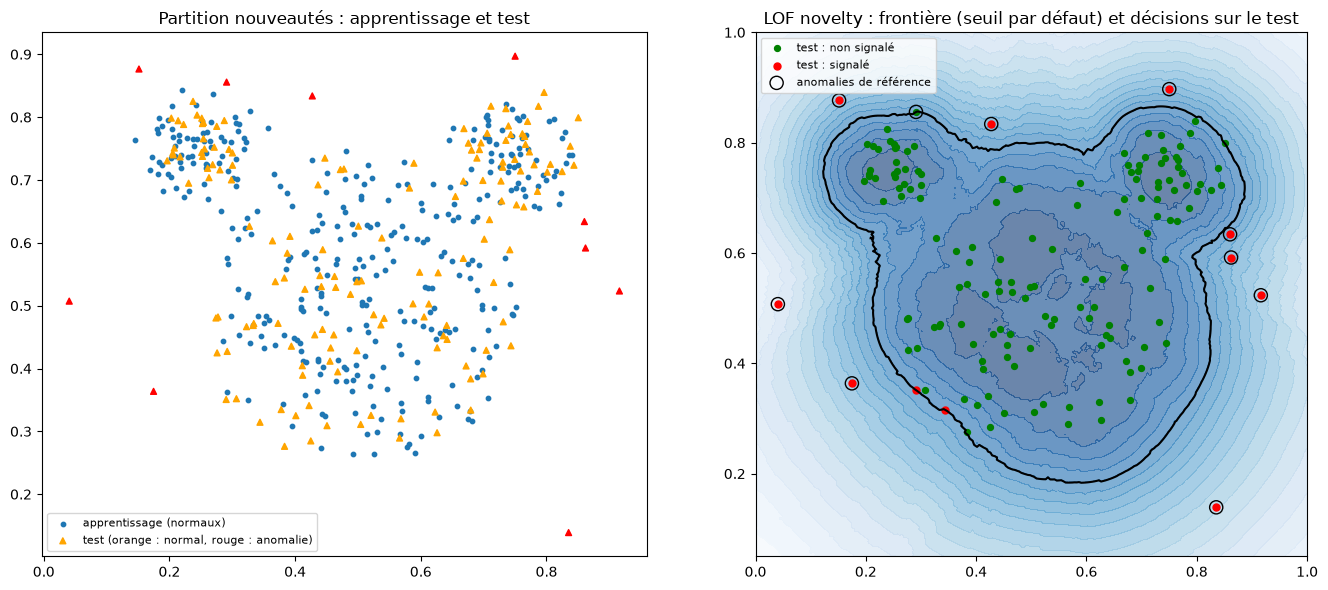

In [7]:
idx_normaux = np.flatnonzero(y_mouse == 0)
idx_app_mouse, idx_test_normaux = train_test_split(idx_normaux, test_size=0.3, random_state=GRAINE)
idx_test_mouse = np.concatenate([idx_test_normaux, np.flatnonzero(y_mouse == 1)])
X_app_mouse = X_mouse.iloc[idx_app_mouse]
X_test_mouse, y_test_mouse = X_mouse.iloc[idx_test_mouse], y_mouse.iloc[idx_test_mouse]
print(f"apprentissage : {len(X_app_mouse)} normaux | test : {len(X_test_mouse)} points dont {y_test_mouse.sum()} anomalies")

lof_nov = LocalOutlierFactor(n_neighbors=20, novelty=True)
lof_nov, s_nov, t_app, t_score = entrainer_et_scorer(lof_nov, X_app_mouse, None, {"test": X_test_mouse})
s_nov = s_nov["test"]
s_app_nov = -lof_nov.negative_outlier_factor_
print(f"temps apprentissage : {t_app:.4f} s | temps score : {t_score:.4f} s")

seuils_nov = {"défaut": seuil_defaut(lof_nov), "IQR (apprentissage)": seuil_iqr(s_app_nov)}
lignes = []
for regle, seuil in seuils_nov.items():
    r = rapport_seuil(y_test_mouse, s_nov, seuil)
    lignes.append({"règle": regle, "seuil": seuil, "alertes": r["alertes"], "FP": r["fausses_alertes"],
                   "FN": r["manquees"], "précision": r["precision"], "rappel": r["rappel"], "F1": r["f1"]})
display(pd.DataFrame(lignes).round(3))
print("Classement sur le test :", {k: round(v, 3) for k, v in evaluer(y_test_mouse, s_nov).items()})

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(X_app_mouse.x1, X_app_mouse.x2, c="tab:blue", s=10, label="apprentissage (normaux)")
axes[0].scatter(X_test_mouse.x1, X_test_mouse.x2, c=np.where(y_test_mouse == 1, "red", "orange"), s=18,
                marker="^", label="test (orange : normal, rouge : anomalie)")
axes[0].set(title="Partition nouveautés : apprentissage et test", aspect="equal")
axes[0].legend(fontsize=8)

# Frontière de décision au seuil par défaut, sur une grille
xx, yy = np.meshgrid(np.linspace(0, 1, 250), np.linspace(0.05, 1, 250))
grille = pd.DataFrame({"x1": xx.ravel(), "x2": yy.ravel()})
zz = score_anomalie(lof_nov, grille).reshape(xx.shape)
axes[1].contourf(xx, yy, np.log(zz), levels=20, cmap="Blues_r", alpha=0.6)
axes[1].contour(xx, yy, zz, levels=[seuils_nov["défaut"]], colors="k", linewidths=1.5)
detectes = s_nov >= seuils_nov["défaut"]
axes[1].scatter(X_test_mouse.x1[~detectes], X_test_mouse.x2[~detectes], c="green", s=18, label="test : non signalé")
axes[1].scatter(X_test_mouse.x1[detectes], X_test_mouse.x2[detectes], c="red", s=25, label="test : signalé")
axes[1].scatter(X_test_mouse.x1[y_test_mouse == 1], X_test_mouse.x2[y_test_mouse == 1], facecolors="none",
                edgecolors="k", s=90, label="anomalies de référence")
axes[1].set(title="LOF novelty : frontière (seuil par défaut) et décisions sur le test", aspect="equal")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Résultats sur le test réservé.** Au seuil par défaut, LOF novelty lève 11 alertes : 9 anomalies sur 10 et
2 points normaux du bas de la tête (zone peu dense). L'anomalie manquée est située juste au-dessus de l'oreille
gauche, à l'intérieur de la frontière apprise : sa densité reste proche de celle de ses voisins normaux.
La règle IQR, calculée sur les scores d'apprentissage, retrouve les 10 anomalies mais au prix de 13 fausses
alertes. Contrairement à la partie 1.c, ces mesures portent sur des points **non utilisés** pour l'ajustement.

*Avertissement « X does not have valid feature names »* : il est émis par sklearn lui-même (`score_samples` de LOF
convertit les données en tableau avant de rechercher les voisins) ; les données passées sont bien celles attendues.

**Outliers ou nouveautés ?**
- En *détection d'outliers*, le détecteur voit tout l'ensemble (anomalies comprises) et classe les points qu'il a
  lui-même utilisés ; les anomalies peuvent déformer la référence (un petit groupe d'anomalies proches peut se
  « protéger » mutuellement en LOF). Il n'existe pas de données nouvelles.
- En *détection de nouveautés*, la référence est supposée propre : le modèle apprend la région normale, puis juge des
  observations jamais vues. Le score `score_samples` (novelty) est alors légitime sur le test, et une frontière
  peut être tracée dans tout le plan.
- Constituer cet apprentissage « normal » demande les **étiquettes** : on a utilisé une information que l'on n'a
  pas en détection d'outliers. Le problème devient semi-supervisé (one-class) : on sait ce qui est normal. En
  pratique, cette référence propre coûte un étiquetage et peut elle-même être contaminée (voir partie 5.1).

---
## Partie 2 : Détection des fraudes (Credit Card)
### 2.1.a Examen des données

In [8]:
brut = pd.read_csv("data/creditcard.csv")
variables_cc = [c for c in brut.columns if c not in ("Time", "Class")]
print("Dimensions :", brut.shape)
print("Types :", brut.dtypes.value_counts().to_dict())
print("Valeurs manquantes :", brut.isna().sum().sum())
print("Fraudes :", brut.Class.sum(), f"({brut.Class.mean():.3%})")
print("Doublons exacts (toutes colonnes) :", brut.duplicated().sum())
print("Doublons sur les variables prédictives (sans Time) :", brut.duplicated(subset=variables_cc).sum())
print("Doublons de variables avec des classes différentes :",
      brut.duplicated(subset=variables_cc).sum() - brut.duplicated(subset=variables_cc + ["Class"]).sum())

Dimensions : (284807, 31)
Types : {dtype('float64'): 30, dtype('int64'): 1}
Valeurs manquantes : 0
Fraudes : 492 (0.173%)


Doublons exacts (toutes colonnes) : 1081


Doublons sur les variables prédictives (sans Time) : 9144


Doublons de variables avec des classes différentes : 0


Time étant écartée des variables prédictives, deux transactions de mêmes V1..V28 et Amount sont identiques pour les
modèles. Si l'une tombait en apprentissage et l'autre en test, le test contiendrait une copie d'un exemple appris :
fuite. Aucun doublon n'a de classes contradictoires, on **garde une seule copie** de chaque transaction (`utils.charger_creditcard`).

In [9]:
X_cc, y_cc, time_cc = utils.charger_creditcard("data/creditcard.csv")
del brut
print("Après dédoublonnage :", X_cc.shape, "| fraudes :", y_cc.sum(), f"({y_cc.mean():.3%})")

parts_cc = utils.decouper_donnees(X_cc, y_cc, graine=GRAINE)
(X_app_cc, y_app_cc), (X_val_cc, y_val_cc), (X_test_cc, y_test_cc) = parts_cc["app"], parts_cc["val"], parts_cc["test"]
display(pd.DataFrame({nom: {"observations": len(y), "fraudes": int(y.sum()), "proportion": y.mean()}
                      for nom, (_, y) in parts_cc.items()}).T)

Après dédoublonnage : (275663, 29) | fraudes : 473 (0.172%)


,observations,fraudes,proportion
app,165397.0,284.0,0.001717
val,55133.0,95.0,0.001723
test,55133.0,94.0,0.001705


### 2.1.b Échelles des variables et prétraitement

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
mean,-0.04,-0.00,0.03,-0.00,-0.01,-0.01,0.01,-0.00,-0.02,0.01,-0.01,-0.01,-0.00,-0.00,-0.01,-0.00,0.00,0.00,0.00,0.00,0.00,0.01,-0.00,-0.01,-0.00,-0.00,0.00,0.00,89.95
std,1.96,1.65,1.51,1.43,1.35,1.30,1.22,1.19,1.10,1.09,1.02,1.00,1.00,0.95,0.92,0.88,0.85,0.84,0.82,0.76,0.73,0.72,0.63,0.61,0.52,0.48,0.40,0.33,240.99
min,-46.86,-47.43,-33.68,-5.56,-40.43,-23.50,-43.56,-50.69,-13.43,-24.59,-4.80,-18.68,-4.01,-18.82,-4.20,-12.68,-25.16,-9.50,-4.93,-28.01,-22.89,-8.89,-36.67,-2.84,-8.70,-2.24,-9.90,-8.66,0.00
50%,-0.06,0.07,0.20,-0.04,-0.06,-0.27,0.04,0.02,-0.07,-0.09,-0.04,0.13,-0.01,0.05,0.04,0.06,-0.06,0.00,0.00,-0.06,-0.03,0.01,-0.01,0.04,0.01,-0.06,0.00,0.01,23.92
max,2.45,22.06,4.23,13.13,34.10,23.92,44.05,20.01,10.39,15.33,11.62,4.85,4.47,7.75,5.83,8.29,9.25,4.30,5.57,24.13,27.20,8.36,22.08,4.02,6.07,3.46,12.15,16.13,11898.09


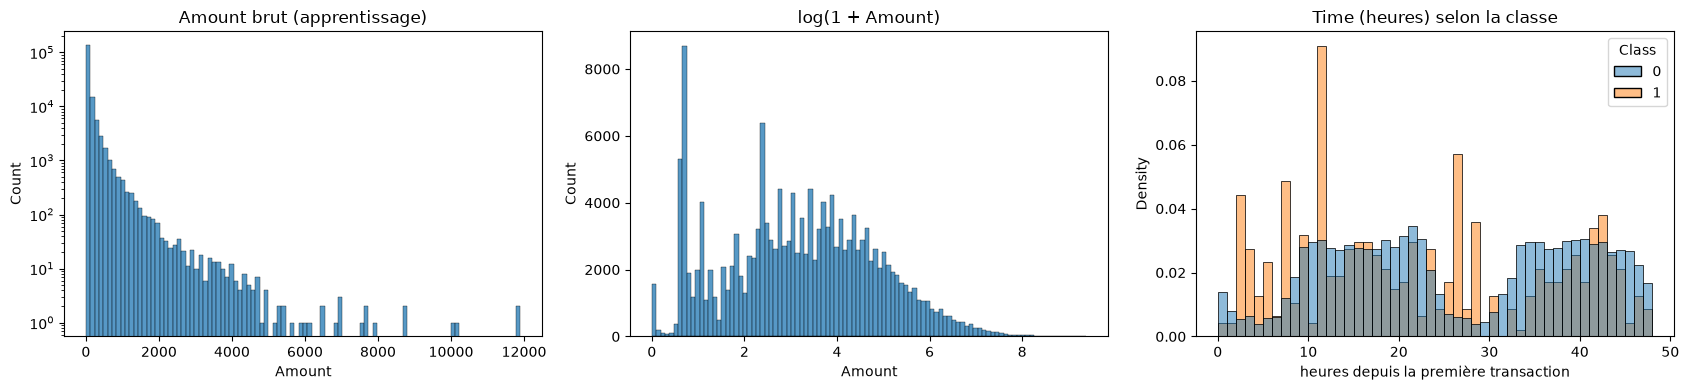

In [10]:
display(X_app_cc.describe().T[["mean", "std", "min", "50%", "max"]].round(2).T)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(X_app_cc.Amount, bins=100, ax=axes[0])
axes[0].set(title="Amount brut (apprentissage)", yscale="log")
sns.histplot(np.log1p(X_app_cc.Amount), bins=100, ax=axes[1])
axes[1].set(title="log(1 + Amount)")
sns.histplot(x=time_cc / 3600, hue=y_cc, stat="density", common_norm=False, bins=48, ax=axes[2])
axes[2].set(title="Time (heures) selon la classe", xlabel="heures depuis la première transaction")
plt.tight_layout()
plt.show()

- V1..V28 sont issues d'une ACP (variables centrées, écarts-types de 0,3 à 2 environ). **Amount** est sur une autre
  échelle (jusqu'à plusieurs milliers) et très asymétrique : on applique `log(1 + Amount)`, transformation fixe sans
  paramètre (pas de fuite).
- **Prétraitement par famille** (ajusté sur l'apprentissage seulement, dans un `Pipeline`) :

| Famille | Prétraitement | Justification |
|---|---|---|
| Arbre de décision | log(Amount) | Coupures par seuil sur une variable : insensible à l'échelle |
| Arbre + SMOTE | log(Amount) + StandardScaler | SMOTE calcule des voisinages : distances à rendre comparables |
| Régression logistique | log(Amount) + StandardScaler | Régularisation L2 et optimisation sensibles à l'échelle |
| Isolation Forest | log(Amount) | Coupures aléatoires entre min et max de chaque variable : échelle sans effet |
| LOF | log(Amount) + StandardScaler | Méthode fondée sur les distances : très sensible à l'échelle |

- **Time** est écartée des variables. Les fraudes n'ont pas la même répartition horaire (creux nocturnes moins
  marqués). Le découpage aléatoire mélange passé et futur : un modèle déployé ne verrait que des transactions
  postérieures à son apprentissage. Nos résultats sont donc probablement optimistes ; un découpage temporel serait
  nécessaire pour une estimation prospective (les données ne couvrent que deux jours).

### 2.2 Configurations comparées
**Supervisés** (6 configurations par modèle = 2 hyperparamètres × 3 traitements du déséquilibre) :
- Arbre de décision : `max_depth` ∈ {4, 8} (arbre peu profond, interprétable, contre un arbre plus expressif ;
  au-delà, un arbre non élagué sur ~300 fraudes surapprend).
- Régression logistique : `C` ∈ {0,01 ; 1} (régularisation forte ou faible).
- Déséquilibre : aucun ; `class_weight="balanced"` (poids N / (K n_i), diapo 33 du cours) ;
  **SMOTE** (`sampling_strategy=0.1`, `k_neighbors=5`). SMOTE crée des fraudes synthétiques par interpolation au
  lieu de dupliquer (RandomOverSampler) ou de jeter ~99 % des transactions normales (RandomUnderSampler). On vise un
  ratio 1 fraude pour 10 normales plutôt qu'un équilibre complet, qui fabriquerait ~160 000 points interpolés à
  partir de moins de 300 fraudes. SMOTE est placé **dans** le Pipeline : il ne s'applique qu'au `fit`, donc
  uniquement à l'apprentissage, après la standardisation (voisinages calculés sur des variables comparables).

**Non supervisés** (ajustés sans étiquettes, sur des transactions normales **et** frauduleuses, sans rééchantillonnage) :
- Isolation Forest sur tout l'apprentissage : `n_estimators` ∈ {100, 300} × `max_samples` ∈ {256, 2048}.
- LOF (`novelty=True`), coûteux : sous-échantillon stratifié fixe de 30 000 transactions de l'apprentissage ;
  `n_neighbors` ∈ {10, 20, 50, 100}. Validation et test restent complets.

**Distinction ajustement / sélection.** IF et LOF sont *ajustés* sans étiquettes, mais choisir leurs
hyperparamètres et leur seuil avec les étiquettes de validation est une *sélection supervisée* : la performance
rapportée n'est donc pas celle d'un système purement non supervisé. Les étiquettes du test ne servent qu'à
l'évaluation finale.

In [11]:
PRECISION_MIN_FRAUDE = 0.80
X_sous_cc, y_sous_cc = utils.sous_echantillon_stratifie(X_app_cc, y_app_cc, n=30_000, graine=GRAINE)
print("Sous-échantillon LOF :", len(X_sous_cc), "transactions dont", y_sous_cc.sum(), "fraudes")


def configurations_supervisees(pretraitement, graine=GRAINE):
    """
    Rôles : Construire les 2 x 6 configurations supervisées (arbre et logistique).
    Saisies :
        - pretraitement : fonction (standardiser) -> étapes de Pipeline (Credit Card ou AI4I)
        - graine : graine aléatoire
    Résultat : liste de configurations pour utils.comparer_configurations
    """
    configs = []
    familles = [
        ("Arbre de décision", "max_depth", [4, 8],
         lambda v, cw: DecisionTreeClassifier(max_depth=v, class_weight=cw, random_state=graine), False),
        ("Régression logistique", "C", [0.01, 1.0],
         lambda v, cw: LogisticRegression(C=v, class_weight=cw, max_iter=2000), True),
    ]
    for famille, param, valeurs, creer, standardiser in familles:
        for v in valeurs:
            for desequilibre in ["aucun", "class_weight", "SMOTE"]:
                cw = "balanced" if desequilibre == "class_weight" else None
                # SMOTE impose une standardisation préalable (voisinages)
                std = standardiser or desequilibre == "SMOTE"
                etapes = list(pretraitement(std))
                if desequilibre == "SMOTE":
                    etapes.append(("smote", SMOTE(sampling_strategy=0.1, k_neighbors=5, random_state=graine)))
                etapes.append(("modele", creer(v, cw)))
                configs.append({"famille": famille, "nom": f"{famille} | {param}={v} | {desequilibre}",
                                "pretraitement": " + ".join(n for n, _ in etapes[:-1] if n != "smote"),
                                "desequilibre": desequilibre, "modele": Pipeline(etapes)})
    return configs


configs_cc = configurations_supervisees(utils.pretraitement_creditcard)
for n_arbres in [100, 300]:
    for max_samples in [256, 2048]:
        configs_cc.append({
            "famille": "Isolation Forest", "nom": f"Isolation Forest | n_estimators={n_arbres}, max_samples={max_samples}",
            "pretraitement": "log_amount", "desequilibre": "aucun (non supervisé)",
            "modele": Pipeline(utils.pretraitement_creditcard(False) + [("modele", IsolationForest(
                n_estimators=n_arbres, max_samples=max_samples, random_state=GRAINE, n_jobs=-1))])})
for k in [10, 20, 50, 100]:
    configs_cc.append({
        "famille": "LOF", "nom": f"LOF | n_neighbors={k}",
        "pretraitement": "log_amount + standard", "desequilibre": "aucun (non supervisé)",
        "app": (X_sous_cc, y_sous_cc),
        "modele": Pipeline(utils.pretraitement_creditcard(True) + [("modele", LocalOutlierFactor(
            n_neighbors=k, novelty=True, n_jobs=-1))])})

resultats_cc, modeles_cc = utils.comparer_configurations(
    configs_cc, (X_app_cc, y_app_cc), (X_val_cc, y_val_cc), PRECISION_MIN_FRAUDE)
colonnes_val = ["nom", "n_app", "ap_val", "auc_roc_val", "seuil", "precision_val", "rappel_val",
                "f1_val", "alertes_val", "atteint", "temps_app_s", "temps_score_val_s"]
display(arrondir(resultats_cc[colonnes_val]))

Sous-échantillon LOF : 30000 transactions dont 52 fraudes


,nom,n_app,ap_val,auc_roc_val,seuil,precision_val,rappel_val,f1_val,alertes_val,atteint,temps_app_s,temps_score_val_s
0,Arbre de décision | max_depth=4 | aucun,165397,0.7206,0.8841,0.600000,0.8590,0.7053,0.7746,78,True,1.5919,0.0062
1,Arbre de décision | max_depth=4 | class_weight,165397,0.5083,0.9267,0.999167,0.6293,0.7684,0.6919,116,False,1.6111,0.0045
2,Arbre de décision | max_depth=4 | SMOTE,165397,0.6072,0.9023,0.987526,0.7579,0.7579,0.7579,95,False,1.8964,0.0048
3,Arbre de décision | max_depth=8 | aucun,165397,0.6387,0.8716,1.000000,0.8452,0.7474,0.7933,84,True,3.1931,0.0045
4,Arbre de décision | max_depth=8 | class_weight,165397,0.5371,0.9147,0.999494,0.6577,0.7684,0.7087,111,False,2.7250,0.0033
5,Arbre de décision | max_depth=8 | SMOTE,165397,0.5732,0.9133,0.994286,0.7579,0.7579,0.7579,95,False,3.4395,0.0054
6,Régression logistique | C=0.01 | aucun,165397,0.7261,0.9658,0.213307,0.8049,0.6947,0.7458,82,True,0.1293,0.0039
7,Régression logistique | C=0.01 | class_weight,165397,0.6780,0.9613,0.999920,0.8022,0.7684,0.7849,91,True,0.1778,0.0035
8,Régression logistique | C=0.01 | SMOTE,165397,0.7210,0.9638,0.994384,0.8023,0.7263,0.7624,86,True,0.3006,0.0035
9,Régression logistique | C=1.0 | aucun,165397,0.7239,0.9636,0.384913,0.8442,0.6842,0.7558,77,True,0.1361,0.0034


### 2.3.a Sélection sur la validation, courbes et seuils
Règle imposée (sur la validation uniquement) : seuil maximisant le rappel sous précision ≥ 80 % avec au moins
une alerte ; départage par la précision puis l'AP. On retient la meilleure configuration de chaque famille.
Les configurations qui atteignent l'objectif passent d'abord. Si l'objectif est inaccessible, on classe par
F1 de validation décroissant, puis rappel, précision et AP, sans prétendre satisfaire la contrainte.

,n_app,ap_val,auc_roc_val,seuil,precision_val,rappel_val,f1_val,alertes_val,atteint,temps_app_s,temps_score_val_s
famille,,,,,,,,,,,
Régression logistique,165397,0.6762,0.9619,0.999968,0.8000,0.8000,0.8000,95,True,0.1939,0.0034
Arbre de décision,165397,0.6387,0.8716,1.000000,0.8452,0.7474,0.7933,84,True,3.1931,0.0045
LOF,30000,0.3825,0.9487,2.796372,0.4336,0.6526,0.5210,143,False,0.4272,0.8486
Isolation Forest,165397,0.2086,0.9493,0.649011,0.2991,0.3368,0.3168,107,False,0.7270,0.4595


Méthode sélectionnée sur la validation : Régression logistique | C=1.0 | class_weight


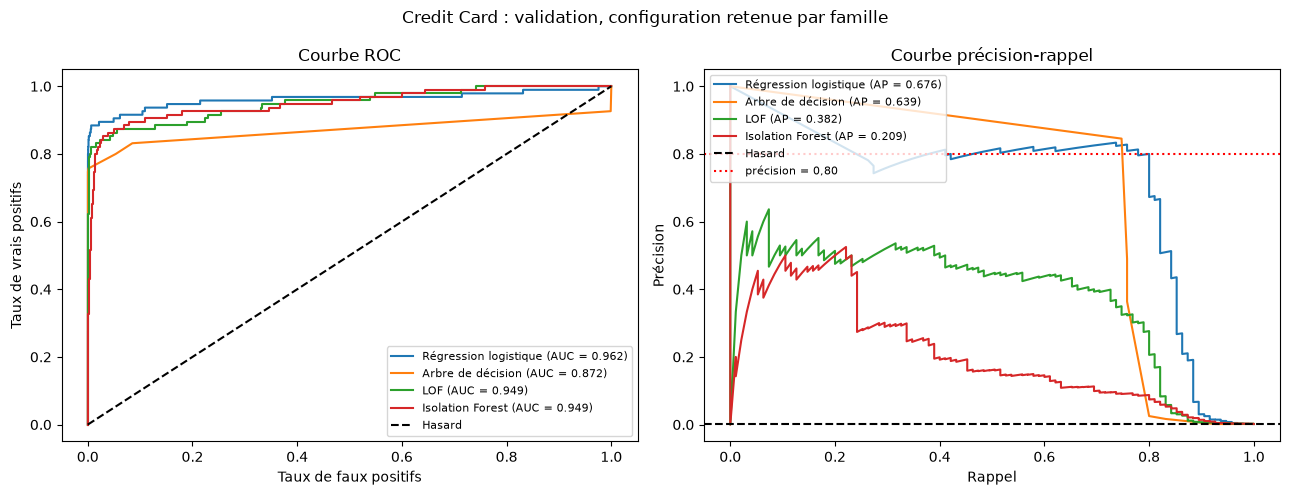

In [12]:
classement_cc = selectionner(resultats_cc)
retenues_cc = classement_cc.groupby("famille", sort=False).head(1).set_index("famille")
display(arrondir(retenues_cc[colonnes_val[1:]]))
methode_selectionnee_cc = retenues_cc.index[0]
print("Méthode sélectionnée sur la validation :", retenues_cc.loc[methode_selectionnee_cc, "nom"])

scores_val_cc = {fam: score_anomalie(modeles_cc[ligne["nom"]], X_val_cc) for fam, ligne in retenues_cc.iterrows()}
fig = tracer_courbes(y_val_cc, scores_val_cc, "Credit Card : validation, configuration retenue par famille")
for ax in fig.axes[1:]:
    ax.axhline(PRECISION_MIN_FRAUDE, color="red", linestyle=":", label="précision = 0,80")
    ax.legend(fontsize=8)
plt.show()

**F1 et balanced accuracy en fonction du seuil** (Isolation Forest retenu, validation).

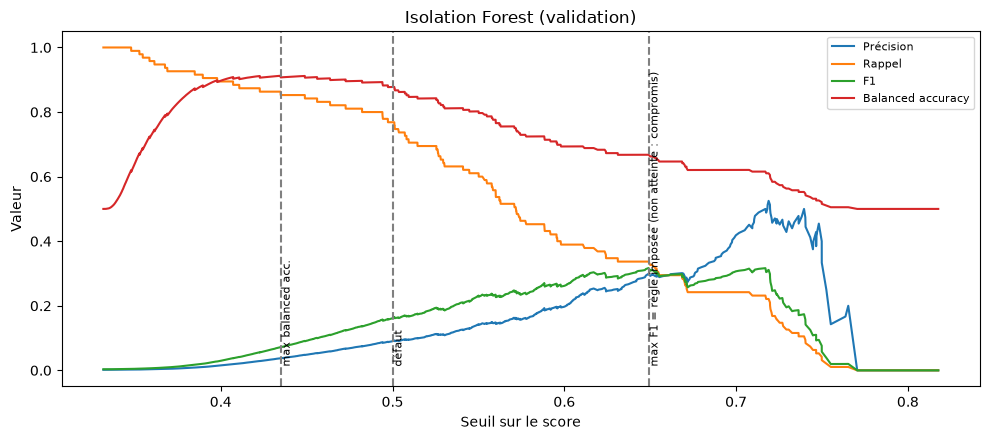

,precision,rappel,f1,balanced_accuracy,alertes
max F1,0.299065,0.336842,0.316832,0.66774,107.0
max balanced acc.,0.037563,0.863158,0.071993,0.912492,2183.0
règle imposée (non atteinte : compromis),0.299065,0.336842,0.316832,0.66774,107.0
défaut,0.090235,0.768421,0.161504,0.877524,809


Régression logistique : max F1 au seuil 0.999968 | max balanced accuracy au seuil 0.825068


,precision,rappel,f1,balanced_accuracy,alertes
0.999968,0.800,0.800,0.800,0.900,95.0
0.825068,0.191,0.884,0.315,0.939,439.0


In [13]:
s_if_val = scores_val_cc["Isolation Forest"]
table_if = utils.metriques_par_seuil(y_val_cc, s_if_val)
seuils_if = {
    "max F1": table_if.f1.idxmax(),
    "max balanced acc.": table_if.balanced_accuracy.idxmax(),
    "règle imposée (non atteinte : compromis)": retenues_cc.loc["Isolation Forest", "seuil"],
    "défaut": seuil_defaut(modeles_cc[retenues_cc.loc["Isolation Forest", "nom"]]),
}
# Un seul repère par seuil (la règle non atteinte retombe sur le maximum du F1)
reperes = {}
for nom, t in seuils_if.items():
    reperes.setdefault(t, []).append(nom)
fig = tracer_metriques_seuil(y_val_cc, s_if_val, "Isolation Forest (validation)",
                             {" = ".join(noms): t for t, noms in reperes.items()})
plt.show()
display(pd.DataFrame({nom: table_if.loc[t] if t in table_if.index else rapport_seuil(y_val_cc, s_if_val, t)
                      for nom, t in seuils_if.items()}).T[["precision", "rappel", "f1", "balanced_accuracy", "alertes"]].round(3))

s_sup_val = scores_val_cc[methode_selectionnee_cc]
table_sup = utils.metriques_par_seuil(y_val_cc, s_sup_val)
print(f"{methode_selectionnee_cc} : max F1 au seuil {table_sup.f1.idxmax():.6f} | "
      f"max balanced accuracy au seuil {table_sup.balanced_accuracy.idxmax():.6f}")
display(table_sup.loc[[table_sup.f1.idxmax(), table_sup.balanced_accuracy.idxmax()]].round(3))

### 2.3.b Seuil retenu contre seuil par défaut (validation)

In [14]:
lignes = []
for fam, ligne in retenues_cc.iterrows():
    modele = modeles_cc[ligne["nom"]]
    for regle, seuil in [("défaut", seuil_defaut(modele)), ("précision ≥ 0,8", ligne["seuil"])]:
        r = rapport_seuil(y_val_cc, scores_val_cc[fam], seuil)
        lignes.append({"famille": fam, "règle": regle, "seuil": seuil, "alertes": r["alertes"],
                       "précision": r["precision"], "rappel": r["rappel"], "F1": r["f1"],
                       "fausses alertes": r["fausses_alertes"], "fraudes manquées": r["manquees"]})
display(arrondir(pd.DataFrame(lignes)))

,famille,règle,seuil,alertes,précision,rappel,F1,fausses alertes,fraudes manquées
0,Régression logistique,défaut,0.500000,1447,0.0587,0.8947,0.1102,1362,10
1,Régression logistique,"précision ≥ 0,8",0.999968,95,0.8000,0.8000,0.8000,19,19
2,Arbre de décision,défaut,0.500000,84,0.8452,0.7474,0.7933,13,24
3,Arbre de décision,"précision ≥ 0,8",1.000000,84,0.8452,0.7474,0.7933,13,24
4,LOF,défaut,1.500000,2550,0.0318,0.8526,0.0612,2469,14
5,LOF,"précision ≥ 0,8",2.796372,143,0.4336,0.6526,0.5210,81,33
6,Isolation Forest,défaut,0.500000,809,0.0902,0.7684,0.1615,736,22
7,Isolation Forest,"précision ≥ 0,8",0.649011,107,0.2991,0.3368,0.3168,75,63


### 2.3.c Évaluation finale sur le test
Les configurations et seuils ci-dessus sont **figés** ; le test est consulté pour la première fois ici.

In [15]:
def tableau_test(retenues, modeles, X_test, y_test):
    """
    Rôles : Évaluer sur le test les configurations retenues, avec leur seuil figé.
    Saisies :
        - retenues : DataFrame des configurations retenues (index = famille)
        - modeles : dictionnaire {nom : modèle entraîné}
        - X_test, y_test : données de test
    Résultat : DataFrame au format du tableau final demandé
    """
    lignes = []
    for fam, ligne in retenues.iterrows():
        debut = time.perf_counter()
        s = score_anomalie(modeles[ligne["nom"]], X_test)
        temps_score = time.perf_counter() - debut
        ev = utils.ligne_evaluation(y_test, s, ligne["seuil"])
        print(f"Matrice de confusion — {ligne['nom']} (lignes : réel, colonnes : prédit)")
        display(pd.DataFrame(rapport_seuil(y_test, s, ligne["seuil"])["matrice"],
                             index=["normal réel", "anomalie réelle"],
                             columns=["normal prédit", "anomalie prédite"]))
        lignes.append({
            "méthode": ligne["nom"], "prétraitement": ligne["pretraitement"],
            "déséquilibre": ligne["desequilibre"], "AP": ev["ap"], "AUC-ROC": ev["auc_roc"],
            "seuil": ligne["seuil"], "précision": ev["precision"], "rappel": ev["rappel"], "F1": ev["f1"],
            "balanced acc.": ev["balanced_accuracy"], "alertes": ev["alertes"],
            "fausses alertes": ev["fausses_alertes"], "manqués": ev["manquees"],
            "objectif val.": "atteint" if ligne["atteint"] else "non atteint",
            "temps app. (s)": ligne["temps_app_s"], "temps score test (s)": temps_score,
            "sélectionnée": "oui" if fam == retenues.index[0] else "",
        })
    return pd.DataFrame(lignes)


final_cc = tableau_test(retenues_cc, modeles_cc, X_test_cc, y_test_cc)
display(arrondir(final_cc))

Matrice de confusion — Régression logistique | C=1.0 | class_weight (lignes : réel, colonnes : prédit)


,normal prédit,anomalie prédite
normal réel,55019,20
anomalie réelle,25,69


Matrice de confusion — Arbre de décision | max_depth=8 | aucun (lignes : réel, colonnes : prédit)


,normal prédit,anomalie prédite
normal réel,55033,6
anomalie réelle,25,69


Matrice de confusion — LOF | n_neighbors=100 (lignes : réel, colonnes : prédit)


,normal prédit,anomalie prédite
normal réel,54973,66
anomalie réelle,36,58


Matrice de confusion — Isolation Forest | n_estimators=300, max_samples=2048 (lignes : réel, colonnes : prédit)


,normal prédit,anomalie prédite
normal réel,54979,60
anomalie réelle,79,15


,méthode,prétraitement,déséquilibre,AP,AUC-ROC,seuil,précision,rappel,F1,balanced acc.,alertes,fausses alertes,manqués,objectif val.,temps app. (s),temps score test (s),sélectionnée
0,Régression logistique | C=1.0 | class_weight,log_amount + standard,class_weight,0.6798,0.9835,0.999968,0.7753,0.7340,0.7541,0.8668,89,20,25,atteint,0.1939,0.0062,oui
1,Arbre de décision | max_depth=8 | aucun,log_amount,aucun,0.6811,0.8439,1.000000,0.9200,0.7340,0.8166,0.8670,75,6,25,atteint,3.1931,0.0039,
2,LOF | n_neighbors=100,log_amount + standard,aucun (non supervisé),0.3295,0.9396,2.796372,0.4677,0.6170,0.5321,0.8079,124,66,36,non atteint,0.4272,0.7106,
3,"Isolation Forest | n_estimators=300, max_sampl...",log_amount,aucun (non supervisé),0.1524,0.9430,0.649011,0.2000,0.1596,0.1775,0.5792,75,60,79,non atteint,0.7270,0.4927,


### 2.3.d Lecture en nombres de transactions
Voir l'analyse après le tableau : elle est rédigée à partir des valeurs ci-dessus (test : 55 133 transactions, 94 fraudes).

In [16]:
for _, ligne in final_cc.iterrows():
    print(f"{ligne['méthode']}\n   {ligne['alertes']} alertes à examiner, dont {ligne['fausses alertes']} inutiles ; "
          f"{ligne['manqués']} fraudes sur {int(y_test_cc.sum())} échappent à la détection "
          f"(précision {ligne['précision']:.1%}, rappel {ligne['rappel']:.1%})")

Régression logistique | C=1.0 | class_weight
   89 alertes à examiner, dont 20 inutiles ; 25 fraudes sur 94 échappent à la détection (précision 77.5%, rappel 73.4%)
Arbre de décision | max_depth=8 | aucun
   75 alertes à examiner, dont 6 inutiles ; 25 fraudes sur 94 échappent à la détection (précision 92.0%, rappel 73.4%)
LOF | n_neighbors=100
   124 alertes à examiner, dont 66 inutiles ; 36 fraudes sur 94 échappent à la détection (précision 46.8%, rappel 61.7%)
Isolation Forest | n_estimators=300, max_samples=2048
   75 alertes à examiner, dont 60 inutiles ; 79 fraudes sur 94 échappent à la détection (précision 20.0%, rappel 16.0%)


**Analyse (Partie 2).**
- *Classement (validation).* Les modèles supervisés dominent nettement en AP (0,51 à 0,73) ; IF et LOF ont
  une AUC-ROC élevée (≈ 0,95) mais une AP faible (0,2 à 0,4). L'AUC-ROC est flatteuse ici : avec 0,17 % de
  fraudes, un taux de faux positifs de 1 % représente déjà ~550 fausses alertes, soit 5 fois plus que de fraudes.
  L'AP, qui regarde la précision des alertes, est la mesure pertinente.
- *LOF et la taille du voisinage.* Avec k = 10 l'AUC est proche du hasard (0,53). Une hypothèse est que
  certaines fraudes forment de petits groupes, masquant leur anomalie locale. Un voisinage plus large pourrait
  inclure davantage de transactions normales. Les métriques seules ne démontrent pas ce mécanisme.
- *Correction du déséquilibre.* Pour la logistique, l'AP varie peu (0,68 à 0,73) : pondérer ou rééchantillonner
  déplace surtout les probabilités vers 1, ce qui change le seuil utile mais peu le classement. Pour l'arbre, la
  pondération et SMOTE dégradent l'AP : l'arbre multiplie les feuilles « fraude » peu pures.
- *F1, balanced accuracy et objectif.* Sur IF, le maximum de la balanced accuracy est obtenu avec ~2 200 alertes
  (rappel 0,86, précision 0,04) : la BA moyenne les rappels des deux classes et ne voit presque pas les fausses alertes,
  noyées dans 55 000 transactions normales. Le F1 privilégie un compromis précision / rappel symétrique. L'objectif
  opérationnel est une **contrainte** (précision ≥ 0,8) puis un maximum de rappel : aucun des deux maxima ne la
  garantit.
- *Seuil par défaut.* Le seuil 0,5 de la logistique pondérée produit 1 447 alertes (précision 0,06) : la pondération
  rend le modèle très « alarmiste », le seuil doit être relevé (≈ 0,99997). Pour IF (score original 0,5) et LOF
  (LOF > 1,5), le seuil par défaut produit des centaines ou des milliers d'alertes. Pour l'arbre sans pondération,
  seuil par défaut et seuil retenu coïncident (feuilles pures). Les probabilités d'un arbre ne prennent que quelques
  valeurs (une par feuille), ce qui rend le choix de seuil grossier.
- *Objectif non atteint* pour IF et LOF : nous rapportons leur meilleur compromis (seuil au F1 maximal) sans
  abaisser la contrainte.
- *Test.* La méthode sélectionnée (logistique, C = 1, `class_weight`) atteignait exactement 0,80 de précision sur la
  validation (76 fraudes sur 95 alertes) : marge nulle. Sur le test, la précision tombe à 0,775, sous la contrainte.
  C'est la fragilité annoncée : avec ~95 fraudes par partition, une ou deux alertes de plus ou de moins suffisent à
  franchir le seuil de 0,80. Nous ne modifions pas le seuil après coup. L'arbre (profondeur 8), deuxième sur la
  validation, respecte la contrainte sur le test (0,92) avec le même rappel.

---
## Partie 3 : Une méthode non vue en cours : HBOS
### 3.a-b Principe, hypothèses, score
**Histogram-Based Outlier Score** (Goldstein, M. et Dengel, A., *HBOS: A Fast Unsupervised Anomaly Detection
Algorithm*, KI-2012 Poster and Demo Track, p. 59-63 ; implémentation de référence : `pyod.models.hbos`,
https://pyod.readthedocs.io/en/latest/pyod.models.html#module-pyod.models.hbos).

- **Principe.** Pour chaque variable j, on construit un histogramme univarié sur l'apprentissage (cases de même
  largeur), normalisé pour que la case la plus haute vaille 1. Une observation tombant dans une case peu remplie
  a une valeur rare pour cette variable.
- **Score.** $\mathrm{HBOS}(x) = \sum_{j=1}^{d} \log\frac{1}{\mathrm{hist}_j(x_j) + \alpha}$, soit
  $-\log \prod_j \hat p_j(x_j)$ à une constante près : log-vraisemblance négative sous l'hypothèse d'indépendance.
  Le lissage $\alpha$ évite $\log(0)$ ; une valeur hors de la plage d'apprentissage reçoit une hauteur nulle.
  Score élevé = observation suspecte (on renvoie $-$HBOS dans `score_samples` pour suivre la convention sklearn).
- **Hypothèses.** (i) Variables **indépendantes** : HBOS ne voit pas une combinaison inhabituelle de valeurs
  individuellement banales. (ii) Anomalies = valeurs **rares** sur au moins une variable. (iii) Densité bien
  représentée par un histogramme à largeur fixe.

Notre implémentation (`utils.HBOS`, ~40 lignes numpy) suit cette définition (histogrammes statiques).

### 3.c Intérêt attendu sur Credit Card, hyperparamètres
- V1..V28 sont des composantes d'ACP, donc **décorrélées** : l'hypothèse d'indépendance, fausse en général, est ici
  assez raisonnable (décorrélation n'est pas indépendance, mais les interactions linéaires sont retirées).
- Coût **linéaire** en n et d, sans calcul de distances : HBOS tient sur tout l'apprentissage (165 000 lignes), là où
  LOF exige un sous-échantillon. Le score est **additif** : on lit directement la contribution de chaque variable.
- Hyperparamètres : **`n_bins`** (trop peu de cases : les queues sont noyées dans la case extrême ; trop de cases :
  histogramme bruité, cases vides dans la masse) et **`alpha`** (poids des cases vides). On teste
  `n_bins` ∈ {10, 50, 200} avec `alpha` = 0,1 (3 configurations).

In [17]:
configs_hbos = [{
    "famille": "HBOS", "nom": f"HBOS | n_bins={b}, alpha=0.1", "pretraitement": "log_amount",
    "desequilibre": "aucun (non supervisé)",
    "modele": Pipeline(utils.pretraitement_creditcard(False) + [("modele", utils.HBOS(n_bins=b, alpha=0.1))]),
} for b in [10, 50, 200]]
resultats_hbos, modeles_hbos = utils.comparer_configurations(
    configs_hbos, (X_app_cc, y_app_cc), (X_val_cc, y_val_cc), PRECISION_MIN_FRAUDE)
display(arrondir(resultats_hbos[colonnes_val]))

,nom,n_app,ap_val,auc_roc_val,seuil,precision_val,rappel_val,f1_val,alertes_val,atteint,temps_app_s,temps_score_val_s
0,"HBOS | n_bins=10, alpha=0.1",165397,0.1631,0.9501,26.102088,0.2440,0.4316,0.3118,168,False,0.1460,0.0291
1,"HBOS | n_bins=50, alpha=0.1",165397,0.1681,0.9483,39.477502,0.2360,0.4000,0.2969,161,False,0.1849,0.0479
2,"HBOS | n_bins=200, alpha=0.1",165397,0.2008,0.9416,46.664026,0.3441,0.3368,0.3404,93,False,0.2366,0.0647


### 3.d-e Comparaison avec IF et LOF (mêmes partitions, même règle de seuil)

,n_app,ap_val,auc_roc_val,seuil,precision_val,rappel_val,f1_val,alertes_val,atteint,temps_app_s,temps_score_val_s
famille,,,,,,,,,,,
LOF,30000,0.3825,0.9487,2.796372,0.4336,0.6526,0.5210,143,False,0.4272,0.8486
HBOS,165397,0.2008,0.9416,46.664026,0.3441,0.3368,0.3404,93,False,0.2366,0.0647
Isolation Forest,165397,0.2086,0.9493,0.649011,0.2991,0.3368,0.3168,107,False,0.7270,0.4595


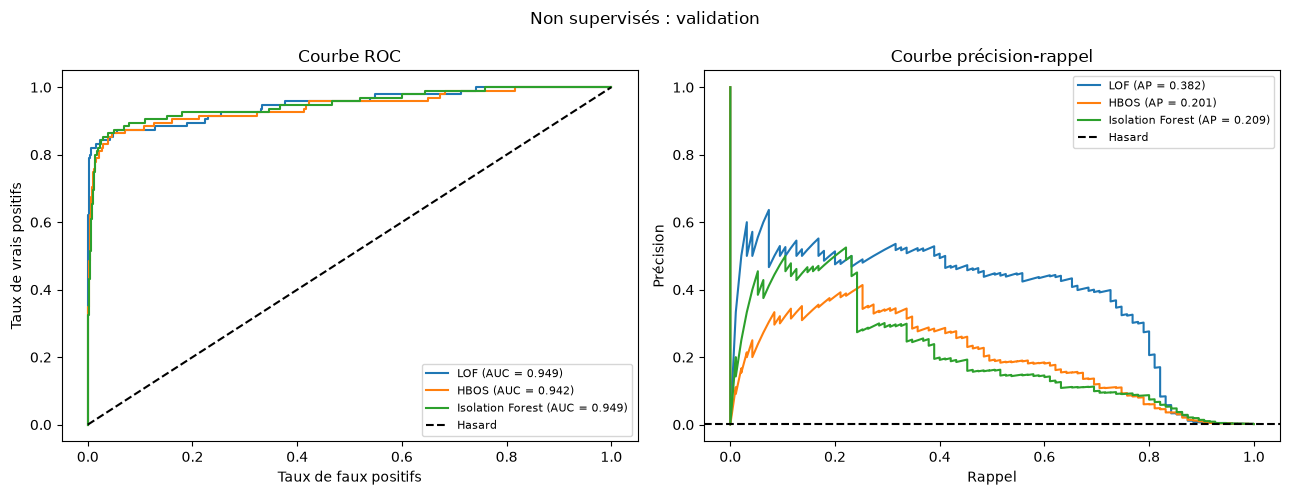

Matrice de confusion — LOF | n_neighbors=100 (lignes : réel, colonnes : prédit)


,normal prédit,anomalie prédite
normal réel,54973,66
anomalie réelle,36,58


Matrice de confusion — HBOS | n_bins=200, alpha=0.1 (lignes : réel, colonnes : prédit)


,normal prédit,anomalie prédite
normal réel,54996,43
anomalie réelle,75,19


Matrice de confusion — Isolation Forest | n_estimators=300, max_samples=2048 (lignes : réel, colonnes : prédit)


,normal prédit,anomalie prédite
normal réel,54979,60
anomalie réelle,79,15


,méthode,prétraitement,déséquilibre,AP,AUC-ROC,seuil,précision,rappel,F1,balanced acc.,alertes,fausses alertes,manqués,objectif val.,temps app. (s),temps score test (s)
0,LOF | n_neighbors=100,log_amount + standard,aucun (non supervisé),0.3295,0.9396,2.796372,0.4677,0.6170,0.5321,0.8079,124,66,36,non atteint,0.4272,0.6963
1,"HBOS | n_bins=200, alpha=0.1",log_amount,aucun (non supervisé),0.1640,0.9265,46.664026,0.3065,0.2021,0.2436,0.6007,62,43,75,non atteint,0.2366,0.0662
2,"Isolation Forest | n_estimators=300, max_sampl...",log_amount,aucun (non supervisé),0.1524,0.9430,0.649011,0.2000,0.1596,0.1775,0.5792,75,60,79,non atteint,0.7270,0.4839


In [18]:
modeles_cc.update(modeles_hbos)
non_sup = pd.concat([resultats_cc[resultats_cc.famille.isin(["Isolation Forest", "LOF"])], resultats_hbos])
retenues_ns = selectionner(non_sup).groupby("famille", sort=False).head(1).set_index("famille")
display(arrondir(retenues_ns[colonnes_val[1:]]))

scores_val_ns = {fam: score_anomalie(modeles_cc[l["nom"]], X_val_cc) for fam, l in retenues_ns.iterrows()}
fig = tracer_courbes(y_val_cc, scores_val_ns, "Non supervisés : validation")
plt.show()

final_ns = tableau_test(retenues_ns, modeles_cc, X_test_cc, y_test_cc).drop(columns="sélectionnée")
display(arrondir(final_ns))

**Une réussite, une limite : contributions par variable (validation).** Le score HBOS étant une somme, on compare
les contributions moyennes des fraudes **détectées** et **manquées** au seuil retenu.

In [19]:
nom_hbos = retenues_ns.loc["HBOS", "nom"]
pipe_hbos = modeles_cc[nom_hbos]
contrib = pd.DataFrame(pipe_hbos[-1].contributions(pipe_hbos[:-1].transform(X_val_cc)), columns=X_val_cc.columns,
                       index=X_val_cc.index)
s_hbos_val = scores_val_ns["HBOS"]
alerte = s_hbos_val >= retenues_ns.loc["HBOS", "seuil"]
groupes = {"fraudes détectées": (y_val_cc == 1) & alerte, "fraudes manquées": (y_val_cc == 1) & ~alerte,
           "normales": y_val_cc == 0}
profil = pd.DataFrame({g: contrib[m].mean() for g, m in groupes.items()})
print({g: int(m.sum()) for g, m in groupes.items()})
top = profil.sort_values("fraudes détectées", ascending=False).head(10)
display(top.round(2))

# Corrélation entre IF et HBOS sur la validation
s_if_val = scores_val_ns["Isolation Forest"]
print("Corrélation de Spearman IF / HBOS :", round(pd.Series(s_if_val).corr(pd.Series(s_hbos_val), method="spearman"), 3))

{'fraudes détectées': 32, 'fraudes manquées': 63, 'normales': 55038}


,fraudes détectées,fraudes manquées,normales
V17,2.30,1.90,0.32
V12,2.30,1.75,0.40
V10,2.30,1.79,0.52
V16,2.30,1.64,0.42
V14,2.30,1.99,0.46
V7,2.29,1.37,0.40
V3,2.29,1.53,0.38
V11,2.29,1.50,0.22
V18,2.28,0.92,0.39
V4,2.24,1.47,0.47


Corrélation de Spearman IF / HBOS : 0.918


**Analyse (Partie 3).**
- *Performance.* Les tableaux de validation comparent AP, AUC et F1. Aucune méthode non supervisée n'atteint
  la précision de 0,80 : la configuration HBOS est donc choisie au meilleur F1 de validation, puis départagée
  par rappel, précision et AP. Le nom effectivement retenu figure dans les tableaux, sans choix sur le test.
- *Réussite.* Le tableau des contributions indique les variables dont les cases peu remplies augmentent
  le score des fraudes détectées par rapport aux transactions normales. HBOS rend ainsi son score lisible.
- *Limite.* Les fraudes manquées ont une somme de contributions sous le seuil. Elles ne sont pas forcément
  banales sur chaque variable. HBOS ne modélise pas les dépendances : une combinaison rare de valeurs
  individuellement banales peut lui échapper. Décorrélation par ACP ne signifie pas indépendance.
  La corrélation avec IF est descriptive, elle ne prouve pas que leurs mécanismes sont identiques.
- *Coût.* HBOS construit des histogrammes et score sans distances entre observations. Les temps mesurés
  dans les tableaux sont à comparer sur cette exécution et avec les tailles d'apprentissage affichées :
  LOF utilise un sous-échantillon, contrairement à HBOS et IF. Aucun rapport de vitesse figé n'est repris.

---
## Partie 4 : Transfert à la maintenance (AI4I 2020)
### 4.a-b Chargement, cible et prétraitement

In [20]:
X_ai, y_ai = utils.charger_ai4i("data/ai4i2020.csv")
print("Dimensions :", X_ai.shape, "| colonnes :", list(X_ai.columns))
print("Pannes :", y_ai.sum(), f"({y_ai.mean():.2%})", "| valeurs manquantes :", X_ai.isna().sum().sum())
display(pd.crosstab(X_ai.Type, y_ai, normalize="index").round(4).rename(columns={0: "sans panne", 1: "panne"}))

# Audit descriptif uniquement : la cible d'origine est conservée.
brut_ai = pd.read_csv("data/ai4i2020.csv")
modes_ai = ["TWF", "HDF", "PWF", "OSF", "RNF"]
ou_modes = brut_ai[modes_ai].any(axis=1).astype(int)
discordances_ai = brut_ai["Machine failure"].ne(ou_modes)
print("Discordances cible / OU des modes :", int(discordances_ai.sum()))
display(pd.crosstab(brut_ai["Machine failure"], ou_modes,
                    rownames=["Machine failure"], colnames=["OU des modes"]))
display(brut_ai.loc[discordances_ai, ["UDI", "Machine failure"] + modes_ai])

parts_ai = utils.decouper_donnees(X_ai, y_ai, graine=GRAINE)
(X_app_ai, y_app_ai), (X_val_ai, y_val_ai), (X_test_ai, y_test_ai) = parts_ai["app"], parts_ai["val"], parts_ai["test"]
display(pd.DataFrame({nom: {"observations": len(y), "pannes": int(y.sum())} for nom, (_, y) in parts_ai.items()}).T)

Dimensions : (10000, 6) | colonnes : ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Pannes : 339 (3.39%) | valeurs manquantes : 0


Machine failure,sans panne,panne
Type,,
H,0.9791,0.0209
L,0.9608,0.0392
M,0.9723,0.0277


Discordances cible / OU des modes : 27


OU des modes,0,1
Machine failure,,
0,9643,18
1,9,330


,UDI,Machine failure,TWF,HDF,PWF,OSF,RNF
1221,1222,0,0,0,0,0,1
1302,1303,0,0,0,0,0,1
1437,1438,1,0,0,0,0,0
1748,1749,0,0,0,0,0,1
2072,2073,0,0,0,0,0,1
2559,2560,0,0,0,0,0,1
2749,2750,1,0,0,0,0,0
3065,3066,0,0,0,0,0,1
3452,3453,0,0,0,0,0,1
4044,4045,1,0,0,0,0,0


,observations,pannes
app,6000,203
val,2000,68
test,2000,68


- Cible : `Machine failure`. Retirés des entrées : `UDI`, `Product ID` (identifiants) et `TWF`, `HDF`, `PWF`, `OSF`,
  `RNF` (types de panne, connus seulement *après* la panne : fuite de la cible).
- Audit des modes : **27 discordances** avec leur OU logique : 18 lignes de cible 0 ont `RNF=1`,
  et 9 lignes de cible 1 ont tous les modes à 0 (exemples : UDI 1222 et 1438).
  Nous conservons `Machine failure` telle quelle et toutes les lignes : reconstruire la cible ou supprimer
  ces cas modifierait arbitrairement la tâche. Les modes servent seulement à cet audit, jamais aux entrées.
- `Type` (L, M, H) : encodage one-hot. Variables numériques (températures, vitesse, couple, usure) : standardisées
  pour la logistique, laissées brutes pour Isolation Forest. Tout est ajusté sur l'apprentissage (`ColumnTransformer`
  dans le `Pipeline`).
- Les observations sont **synthétiques** (générées pour reproduire des mécanismes de panne connus) : les conclusions
  ne se transposent pas telles quelles à une vraie ligne de production.

### 4.c Modèles réutilisés
On reprend la configuration supervisée sélectionnée sur la validation de Credit Card et l'Isolation Forest retenu,
avec **les mêmes hyperparamètres**, mais réajustés (modèle et transformations) sur AI4I. Le seuil est rechoisi.

In [21]:
def transposer_ai4i(pipeline_cc):
    """
    Rôles : Recréer une configuration Credit Card pour AI4I (mêmes hyperparamètres, prétraitement AI4I).
    Saisies :
        - pipeline_cc : Pipeline entraîné sur Credit Card
    Résultat : Pipeline non entraîné pour AI4I
    """
    noms = [nom for nom, _ in pipeline_cc.steps]
    etapes = utils.pretraitement_ai4i(standardiser="standard" in noms)
    # Rééchantillonnage éventuel et modèle : clonés (hyperparamètres conservés, apprentissage oublié)
    etapes += [(nom, clone(etape)) for nom, etape in pipeline_cc.steps if nom in ("smote", "modele")]
    return Pipeline(etapes)


PRECISION_MIN_PANNE = 0.90
supervises_cc = retenues_cc[retenues_cc.index.isin(["Arbre de décision", "Régression logistique"])]
nom_sup_cc = supervises_cc["nom"].iloc[0]
nom_if_cc = retenues_cc.loc["Isolation Forest", "nom"]
configs_ai = []
for famille, nom_cc, desequilibre in [
        (supervises_cc.index[0], nom_sup_cc, supervises_cc["desequilibre"].iloc[0]),
        ("Isolation Forest", nom_if_cc, "aucun (non supervisé)")]:
    standard = "standard" in modeles_cc[nom_cc].named_steps
    configs_ai.append({"famille": famille, "nom": nom_cc + " (AI4I)", "desequilibre": desequilibre,
                       "pretraitement": "one-hot Type" + (" + standard" if standard else ""),
                       "modele": transposer_ai4i(modeles_cc[nom_cc])})
for config in configs_ai:
    print(config["nom"], "->", config["modele"])
resultats_ai, modeles_ai = utils.comparer_configurations(
    configs_ai, (X_app_ai, y_app_ai), (X_val_ai, y_val_ai), PRECISION_MIN_PANNE)
display(arrondir(resultats_ai[colonnes_val]))

Régression logistique | C=1.0 | class_weight (AI4I) -> Pipeline(steps=[('colonnes',
                 ColumnTransformer(transformers=[('type',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Type']),
                                                 ('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]'])])),
                ('modele',
                 LogisticRegression(class_weight='balanced', max_iter=2000))])
Isolation Forest | n_estimators=300, max_samples=2048 (AI4I) -> Pipelin

,nom,n_app,ap_val,auc_roc_val,seuil,precision_val,rappel_val,f1_val,alertes_val,atteint,temps_app_s,temps_score_val_s
0,Régression logistique | C=1.0 | class_weight (...,6000,0.4072,0.8811,0.979916,0.9167,0.1618,0.2750,12,True,0.0083,0.0017
1,"Isolation Forest | n_estimators=300, max_sampl...",6000,0.1514,0.7816,0.681207,1.0000,0.0294,0.0571,2,True,0.1990,0.0442


### 4.d Seuil sous précision ≥ 90 % (validation), puis test

Méthode sélectionnée sur la validation AI4I : Régression logistique | C=1.0 | class_weight (AI4I)


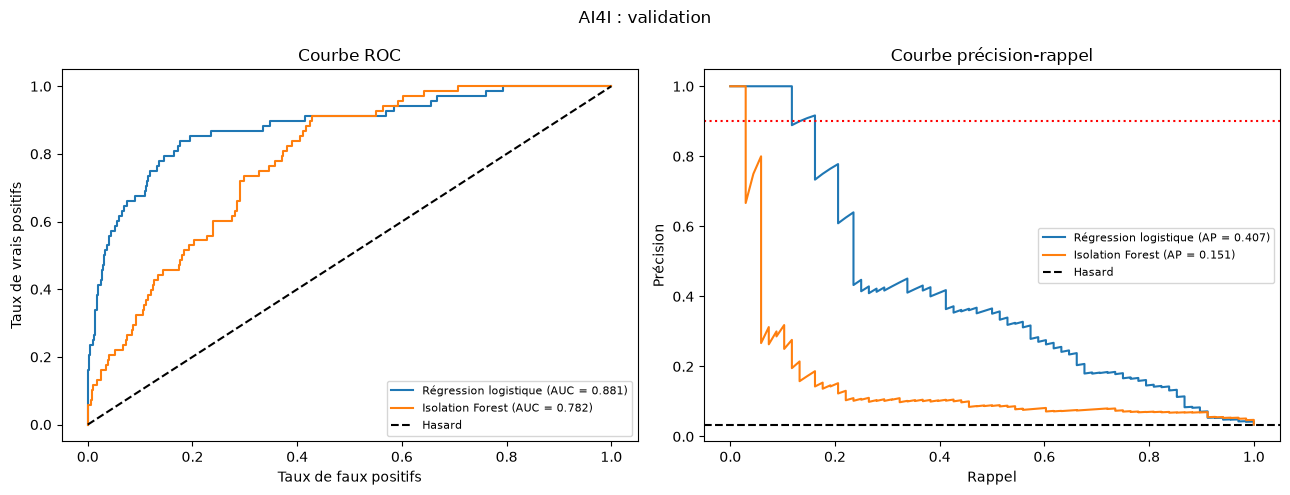

Matrice de confusion — Régression logistique | C=1.0 | class_weight (AI4I) (lignes : réel, colonnes : prédit)


,normal prédit,anomalie prédite
normal réel,1932,0
anomalie réelle,64,4


Matrice de confusion — Isolation Forest | n_estimators=300, max_samples=2048 (AI4I) (lignes : réel, colonnes : prédit)


,normal prédit,anomalie prédite
normal réel,1931,1
anomalie réelle,67,1


,méthode,prétraitement,déséquilibre,AP,AUC-ROC,seuil,précision,rappel,F1,balanced acc.,alertes,interventions inutiles,pannes manquées,objectif val.,temps app. (s),temps score test (s),sélectionnée
0,Régression logistique | C=1.0 | class_weight (...,one-hot Type + standard,class_weight,0.4087,0.9046,0.979916,1.0,0.0588,0.1111,0.5294,4,0,64,atteint,0.0083,0.0022,oui
1,"Isolation Forest | n_estimators=300, max_sampl...",one-hot Type,aucun (non supervisé),0.0919,0.7465,0.681207,0.5,0.0147,0.0286,0.5071,2,1,67,atteint,0.1990,0.0438,


Régression logistique | C=1.0 | class_weight (AI4I) : 4 interventions déclenchées, dont 0 inutiles ; 64 pannes manquées sur 68
Isolation Forest | n_estimators=300, max_samples=2048 (AI4I) : 2 interventions déclenchées, dont 1 inutiles ; 67 pannes manquées sur 68


In [22]:
retenues_ai = selectionner(resultats_ai).set_index("famille")
print("Méthode sélectionnée sur la validation AI4I :", retenues_ai["nom"].iloc[0])
scores_val_ai = {fam: score_anomalie(modeles_ai[l["nom"]], X_val_ai) for fam, l in retenues_ai.iterrows()}
fig = tracer_courbes(y_val_ai, scores_val_ai, "AI4I : validation")
fig.axes[1].axhline(PRECISION_MIN_PANNE, color="red", linestyle=":")
plt.show()

final_ai = tableau_test(retenues_ai, modeles_ai, X_test_ai, y_test_ai).rename(
    columns={"fausses alertes": "interventions inutiles", "manqués": "pannes manquées"})
display(arrondir(final_ai))
for _, ligne in final_ai.iterrows():
    print(f"{ligne['méthode']} : {ligne['alertes']} interventions déclenchées, dont {ligne['interventions inutiles']} "
          f"inutiles ; {ligne['pannes manquées']} pannes manquées sur {int(y_test_ai.sum())}")

### 4.e Pourquoi le gagnant des fraudes n'est pas forcément le meilleur sur les pannes
Contrôle **indicatif**, hors protocole de sélection : un arbre de profondeur 8 (la configuration arbre retenue sur
Credit Card), évalué sur la **validation** AI4I seulement (le test n'est pas consulté).

In [23]:
arbre_ai = transposer_ai4i(modeles_cc[retenues_cc.loc["Arbre de décision", "nom"]])
arbre_ai.fit(X_app_ai, y_app_ai)
s_arbre_ai = score_anomalie(arbre_ai, X_val_ai)
print("Arbre (validation AI4I) :", {k: round(v, 3) for k, v in evaluer(y_val_ai, s_arbre_ai).items()},
      {k: (round(v, 3) if isinstance(v, float) else v)
       for k, v in choisir_seuil_contraint(y_val_ai, s_arbre_ai, PRECISION_MIN_PANNE).items()})

Arbre (validation AI4I) : {'ap': 0.588, 'auc_roc': 0.892} {'seuil': np.float64(0.75), 'precision': np.float64(0.811), 'rappel': np.float64(0.632), 'alertes': 53, 'atteint': False}


**Analyse (Partie 4).**
- *Résultat.* Sur la validation, la logistique pondérée atteint la précision de 0,90, mais seulement avec 12 alertes
  (11 pannes, rappel 0,16) ; IF ne l'atteint qu'avec 2 alertes (rappel 0,03). Ces « succès » reposent sur très
  peu de cas : sur le test, la logistique ne lève que 4 alertes (4 pannes, précision 1,0, rappel 0,06) et laisse
  passer 64 pannes sur 68. L'objectif est formellement atteint, mais il est presque inutile en pratique.
- *Pourquoi la logistique perd sa supériorité.* Dans AI4I, les pannes suivent des règles **non linéaires et
  d'interaction** : dissipation thermique (écart de températures faible *et* vitesse faible), puissance (couple ×
  vitesse hors d'une plage), surcharge (usure × couple au-delà d'un seuil dépendant du `Type`), usure de l'outil
  dans une fenêtre précise. Une frontière linéaire ne peut pas les représenter. L'arbre, qui coupe par seuils et
  combine les variables, obtient la meilleure AP de validation parmi les modèles examinés (0,59 contre 0,41),
  mais **n'atteint pas** la précision de 0,90 : le seuil affiché est un compromis F1, hors sélection.
  Sur Credit Card, la bonne AP de la logistique est compatible avec une séparation plus accessible à ce modèle ;
  elle ne prouve pas que les fraudes sont presque linéairement séparables.
- *Limite observée d'IF.* Son AP de validation est faible (0,15). Une hypothèse est que les combinaisons
  critiques de mesures sont mal isolées par les coupures apprises ici. IF peut détecter des combinaisons
  inhabituelles, pas seulement des valeurs extrêmes ; ces résultats ne prouvent pas une incapacité générale.
- *Comparer les AP des deux jeux n'a pas de sens direct* : l'AP d'un classement aléatoire vaut la proportion de
  positifs (0,17 % pour les fraudes, 3,4 % pour les pannes). Une AP de 0,41 sur AI4I et de 0,68 sur Credit Card ne
  mesurent ni la même difficulté ni le même gain par rapport au hasard. La contrainte de précision (0,90 contre
  0,80) diffère aussi.

---
## Partie 5 : Robustesse et explicabilité
### 5.1 Contaminer la référence normale (Mouse)
- Référence : l'apprentissage normal de la partie 1.3 (343 points). Test : **exactement** le même test réel réservé
  (147 normaux + 10 anomalies), sans aucune injection.
- Contamination r ∈ {0 %, 5 %, 10 %} : on **remplace** r × 343 points normaux tirés au hasard par autant
  d'anomalies synthétiques ; la taille de l'apprentissage reste 343.
- Générateur : loi **uniforme** dans la boîte englobante de la référence normale, élargie de 20 % de chaque côté
  (`utils.generer_anomalies_uniformes`). Choix simple, sans connaissance de la forme des nuages. Une partie des points
  tombe dans les nuages normaux : ce ne sont alors pas de « vraies » anomalies.
- Hyperparamètres fixes : IF (100 arbres, `max_samples="auto"`), LOF (`n_neighbors=20`, `novelty=True`).
  Trois graines (0, 1, 2) : la graine fixe les points remplacés, les anomalies générées et l'aléa d'IF.

ap         auc_roc        
                                  mean     std    mean     std
méthode          contamination                                
Isolation Forest 0.00           0.7790  0.1133  0.9803  0.0096
                 0.05           0.9346  0.0373  0.9948  0.0026
                 0.10           0.9252  0.0400  0.9934  0.0041
LOF              0.00           0.9769  0.0000  0.9980  0.0000
                 0.05           0.9810  0.0165  0.9982  0.0016
                 0.10           0.9923  0.0133  0.9993  0.0012

,méthode,contamination,graine,temps_app_s,temps_score_s
0,Isolation Forest,0.00,0,0.04756,0.00394
1,LOF,0.00,0,0.00103,0.00054
2,Isolation Forest,0.00,1,0.04634,0.00394
3,LOF,0.00,1,0.00101,0.00048
4,Isolation Forest,0.00,2,0.04535,0.00368
5,LOF,0.00,2,0.00098,0.00048
6,Isolation Forest,0.05,0,0.04516,0.00370
7,LOF,0.05,0,0.00106,0.00053
8,Isolation Forest,0.05,1,0.04572,0.00363
9,LOF,0.05,1,0.00101,0.00050


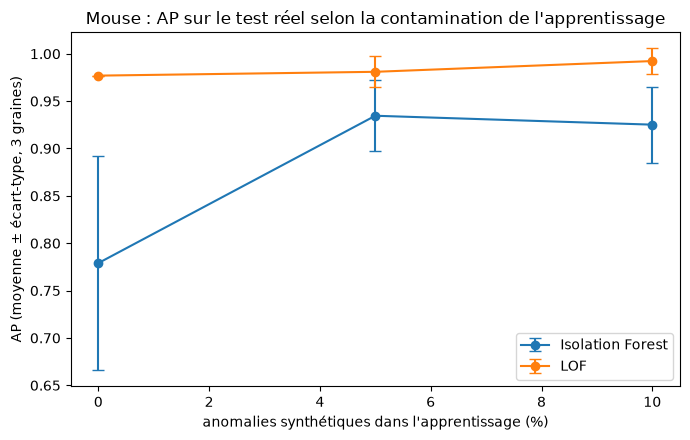

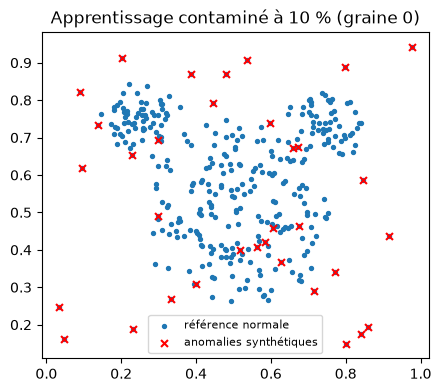

In [24]:
taux_contamination = [0.0, 0.05, 0.10]
graines = [0, 1, 2]
lignes = []
X_ref = X_app_mouse.to_numpy()
for taux in taux_contamination:
    for graine in graines:
        rng = np.random.default_rng(graine)
        n_inj = int(round(taux * len(X_ref)))
        X_cont = X_ref.copy()
        remplaces = rng.choice(len(X_ref), size=n_inj, replace=False)
        X_cont[remplaces] = utils.generer_anomalies_uniformes(X_ref, n_inj, graine=graine)
        detecteurs = {"Isolation Forest": IsolationForest(random_state=graine),
                      "LOF": LocalOutlierFactor(n_neighbors=20, novelty=True)}
        for nom, modele in detecteurs.items():
            modele, sorties, t_app, t_score = entrainer_et_scorer(
                modele, X_cont, None, {"test": X_test_mouse.to_numpy()})
            s = sorties["test"]
            lignes.append({"méthode": nom, "contamination": taux, "graine": graine, "n_injectées": n_inj, "temps_app_s": t_app, "temps_score_s": t_score,
                           **evaluer(y_test_mouse, s)})
robustesse = pd.DataFrame(lignes)
resume = robustesse.groupby(["méthode", "contamination"])[["ap", "auc_roc"]].agg(["mean", "std"])
display(resume.round(4))
display(robustesse[["méthode", "contamination", "graine", "temps_app_s", "temps_score_s"]].round(5))

fig, ax = plt.subplots(figsize=(7, 4.5))
for nom, groupe in robustesse.groupby("méthode"):
    stats = groupe.groupby("contamination")["ap"].agg(["mean", "std"])
    ax.errorbar(stats.index * 100, stats["mean"], yerr=stats["std"], marker="o", capsize=4, label=nom)
ax.set(title="Mouse : AP sur le test réel selon la contamination de l'apprentissage",
       xlabel="anomalies synthétiques dans l'apprentissage (%)", ylabel="AP (moyenne ± écart-type, 3 graines)")
ax.legend()
plt.tight_layout()
plt.show()

# Exemple d'apprentissage contaminé à 10 % (graine 0)
rng = np.random.default_rng(0)
X_exemple = X_ref.copy()
remplaces = rng.choice(len(X_ref), size=34, replace=False)
X_exemple[remplaces] = utils.generer_anomalies_uniformes(X_ref, 34, graine=0)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(*X_exemple.T, s=8, c="tab:blue", label="référence normale")
ax.scatter(*X_exemple[remplaces].T, s=25, c="red", marker="x", label="anomalies synthétiques")
ax.set(title="Apprentissage contaminé à 10 % (graine 0)", aspect="equal")
ax.legend(fontsize=8)
plt.show()

**Analyse (5.1).**
- *LOF* est stable : AP 0,977 sans contamination, 0,981 à 5 %, 0,992 à 10 % (écart-type ≤ 0,017). LOF est
  déterministe, d'où l'écart-type nul à 0 %. Une hypothèse est que les points uniformes perturbent peu les
  voisinages utiles. Leur influence exacte sur les voisins n'a pas été mesurée.
- *IF* s'**améliore** avec la contamination (AP 0,78 ± 0,11 → 0,93 ± 0,04), contre l'intuition. Hypothèse :
  les coupures d'un arbre sont tirées entre le minimum et le maximum des données du nœud. Sans contamination,
  plusieurs anomalies de test sont *hors* de la boîte des points normaux (x1 ≈ 0,04 ou 0,92, x2 ≈ 0,14) : elles
  tombent dans la même feuille que les points du bord et héritent de leur profondeur. Les anomalies synthétiques
  étendent la boîte de 20 % : des coupures sont alors tirées dans les zones vides, où les vraies anomalies sont
  isolées vite. La forte dispersion à 0 % (3 graines) montre aussi qu'IF est sensible à son aléa sur 343 points.
- *Dépendance au générateur.* Le résultat porte uniquement sur cette injection uniforme. Des points groupés
  ou proches des nuages pourraient modifier les conclusions : cela n'a pas été testé. Un petit groupe peut
  masquer ses membres pour LOF si leur voisinage reste dans le groupe, sans garantie sur le test réel.


### 5.2 Expliquer quelques alertes d'Isolation Forest (Credit Card, SHAP)
- Modèle : l'Isolation Forest retenu en partie 2, avec son seuil figé sur la validation.
- **Sortie expliquée.** `shap.TreeExplainer` appliqué à un `IsolationForest` explique la **longueur moyenne de
  chemin** $h(x)$ (profondeur d'isolement moyenne sur les arbres), pas le score final. On le vérifie ci-dessous :
  valeur de base + somme des contributions = $-c(\psi)\log_2(-\texttt{score\_samples}(x))$. Comme
  $s(x) = 2^{-h(x)/c(\psi)}$ (diapo 23), un chemin **court** signifie **suspect** : une contribution SHAP
  **négative** pousse vers l'alerte.
- Référence (fond) : 50 transactions tirées de l'**apprentissage** uniquement, après la même transformation
  `log(1 + Amount)`.

{'fraude détectée': 15, 'fausse alerte': 60, 'fraude manquée': 79}


Écart max entre base + somme SHAP et h(x) : 2.5795097080560936e-07
Valeur de base E[h(x)] sur le fond : 21.017


,fraude détectée #1,fraude détectée #2,fausse alerte #1,fausse alerte #2,fraude manquée #1,fraude manquée #2
h(x),4.798,5.976,4.988,5.156,21.772,21.745
score orienté,0.794,0.750,0.787,0.780,0.351,0.351


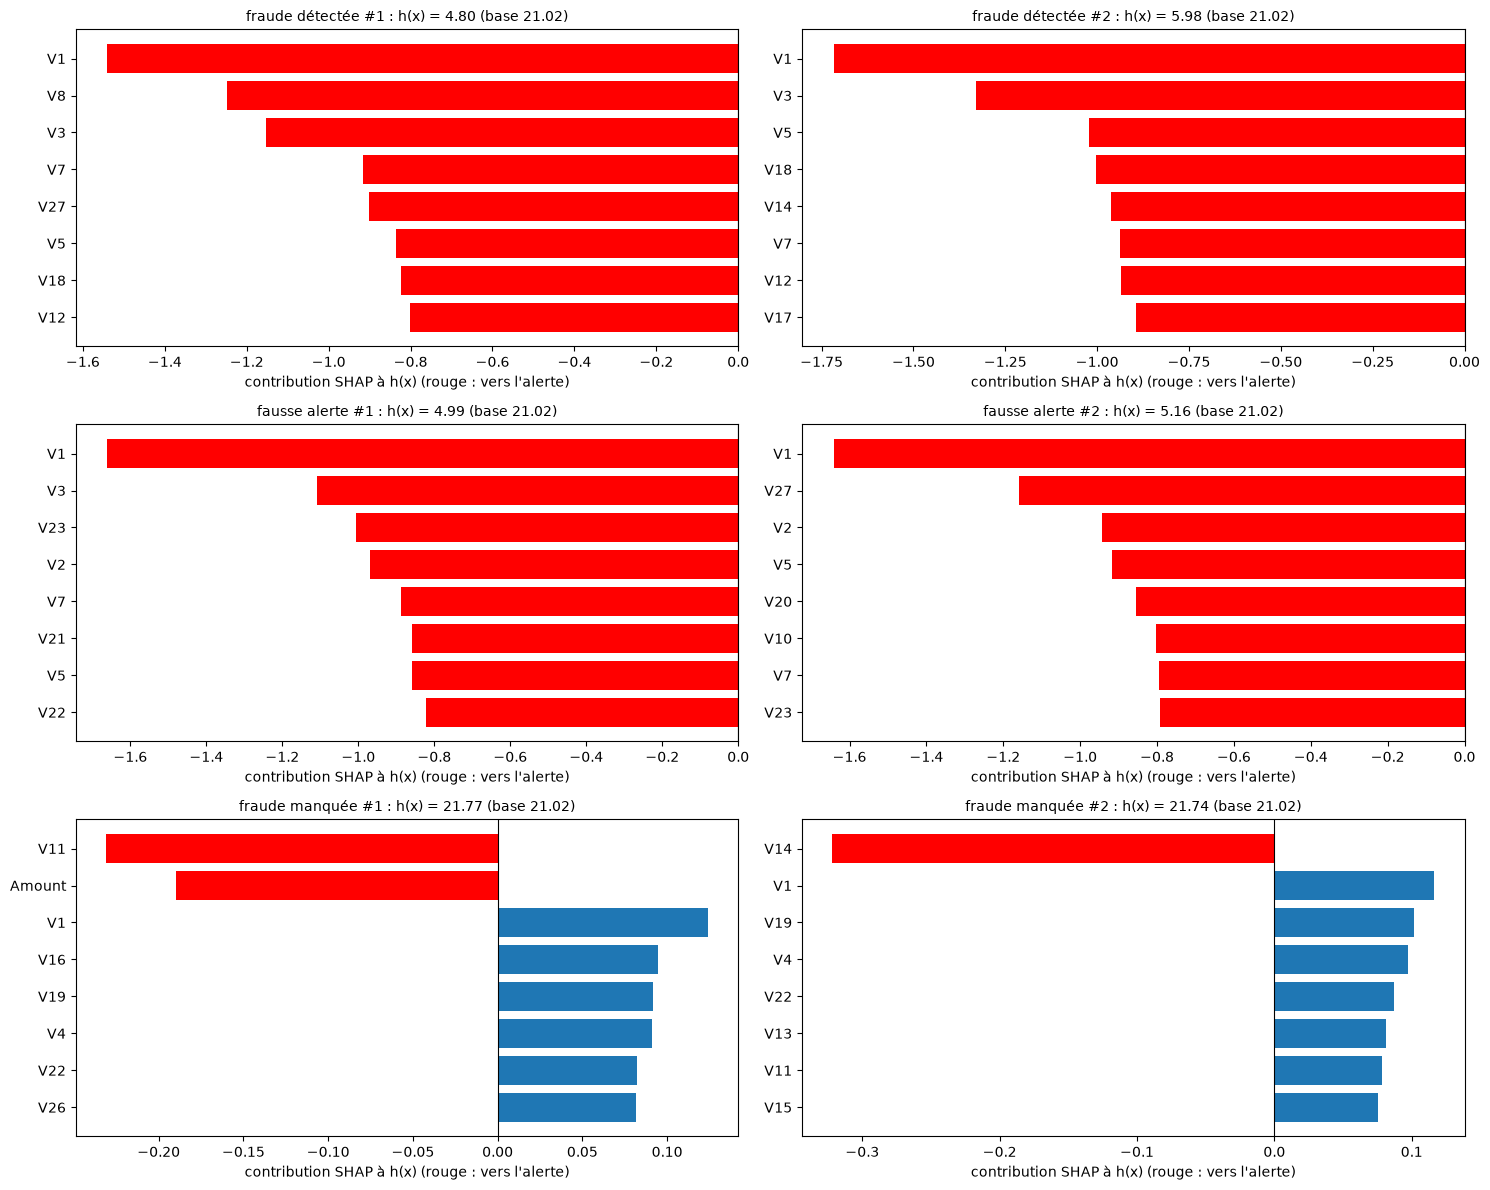

,fraude détectée,fausse alerte,fraude manquée
V1,1.629,1.651,0.000
V3,1.241,0.823,0.000
V8,0.973,0.200,0.000
V5,0.930,0.888,0.000
V7,0.928,0.841,0.037
V18,0.914,0.226,0.029
V12,0.868,0.202,0.000
V17,0.803,0.097,0.011


In [25]:
pipe_if = modeles_cc[retenues_cc.loc["Isolation Forest", "nom"]]
iforest = pipe_if[-1]
seuil_if = retenues_cc.loc["Isolation Forest", "seuil"]
s_if_test = score_anomalie(pipe_if, X_test_cc)
alerte_test = s_if_test >= seuil_if

categories = {
    "fraude détectée": np.flatnonzero((y_test_cc == 1) & alerte_test),
    "fausse alerte": np.flatnonzero((y_test_cc == 0) & alerte_test),
    "fraude manquée": np.flatnonzero((y_test_cc == 1) & ~alerte_test),
}
print({cat: len(idx) for cat, idx in categories.items()})
choix = []
for cat, idx in categories.items():
    # Les deux cas les plus nets de chaque catégorie (scores les plus élevés, ou les plus bas pour les manquées)
    ordre = idx[np.argsort(-s_if_test[idx])] if cat != "fraude manquée" else idx[np.argsort(s_if_test[idx])]
    if len(ordre) < 2:
        print(f"Catégorie « {cat} » : seulement {len(ordre)} cas disponible(s)")
    choix += [(cat, i) for i in ordre[:2]]

X_test_log = pipe_if[:-1].transform(X_test_cc)
fond = pipe_if[:-1].transform(X_app_cc.sample(50, random_state=GRAINE))
explicateur = shap.TreeExplainer(iforest, data=fond)
X_expl = X_test_log.iloc[[i for _, i in choix]]
valeurs_shap = explicateur.shap_values(X_expl)

# Vérification de la sortie expliquée
c_psi = 2 * (np.log(iforest.max_samples_ - 1) + np.euler_gamma) - 2 * (iforest.max_samples_ - 1) / iforest.max_samples_
profondeur = -c_psi * np.log2(-iforest.score_samples(X_expl))
print("Écart max entre base + somme SHAP et h(x) :",
      np.abs(explicateur.expected_value + valeurs_shap.sum(axis=1) - profondeur).max())
print("Valeur de base E[h(x)] sur le fond :", round(float(explicateur.expected_value), 3))

tableau_shap = pd.DataFrame(valeurs_shap, columns=X_expl.columns)
tableau_shap.insert(0, "score orienté", s_if_test[[i for _, i in choix]])
tableau_shap.insert(0, "h(x)", profondeur)
tableau_shap.index = [f"{cat} #{k % 2 + 1}" for k, (cat, _) in enumerate(choix)]
display(tableau_shap.round(3).T.head(2))

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
for ax, (etiquette, ligne) in zip(axes.ravel(), tableau_shap.iterrows()):
    contrib = ligne.drop(["h(x)", "score orienté"])
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index[:8])[::-1]
    ax.barh(top.index, top.values, color=np.where(top.values < 0, "red", "tab:blue"))
    ax.axvline(0, color="k", linewidth=0.8)
    ax.set_title(f"{etiquette} : h(x) = {ligne['h(x)']:.2f} (base {float(explicateur.expected_value):.2f})", fontsize=10)
    ax.set_xlabel("contribution SHAP à h(x) (rouge : vers l'alerte)")
plt.tight_layout()
plt.show()

# Variables qui raccourcissent le plus le chemin, par catégorie
pousse_alerte = pd.DataFrame({cat: (-tableau_shap.filter(like=cat, axis=0).drop(columns=["h(x)", "score orienté"]))
                              .clip(lower=0).mean() for cat in categories}).sort_values("fraude détectée", ascending=False)
display(pousse_alerte.head(8).round(3))

**Lecture des six cas (test).** Les trois catégories sont présentes (15 fraudes détectées, 60 fausses alertes, 79
fraudes manquées) ; on explique les deux cas les plus nets de chacune. Les cas sont choisis par leur score et
leur catégorie : l'étiquette de test sert uniquement à les classer, pas à modifier le modèle ou le seuil.
- Les **fraudes détectées** et les **fausses alertes** sélectionnées sont isolées en ≈ 5 coupures au lieu de ≈ 21 :
  leur somme SHAP est négative, mais toutes les contributions ne le sont pas. Les quatre cas ont respectivement
  2, 5, 3 et 3 contributions positives. V1 domine les contributions négatives, suivie notamment de V3, V5 et V7.
- Ce qui distingue les fraudes détectées des fausses alertes est plutôt V8, V18, V12, V17 et V14 ; les fausses
  alertes s'appuient davantage sur V2, V23, V27, V20 ou V21. Sur deux cas par catégorie, ce n'est qu'une indication.
- Les **deux fraudes manquées sélectionnées**, aux scores les plus faibles de cette catégorie, ont une profondeur
  supérieure à la moyenne (h ≈ 21,7) : la plupart des variables allongent le chemin.
  Leur récupération demanderait un seuil très bas, avec beaucoup de fausses alertes. Cela décrit ces deux cas,
  pas l'ensemble des fraudes manquées ; leurs profils ne permettent pas une conclusion générale.

**Ce que SHAP permet, et ce qu'il ne permet pas.**
- SHAP décompose, de façon additive et exacte pour ces arbres, l'écart entre la profondeur d'isolement d'une
  transaction et la profondeur moyenne du fond, en contributions par variable. Il décrit **le fonctionnement du
  modèle** : quelles valeurs ont permis d'isoler vite cette transaction.
- Il ne prouve **aucune causalité** : une variable qui raccourcit le chemin n'est pas « la cause » de la fraude.
  Les variables V1..V28 sont des composantes d'ACP anonymisées : on ne peut pas leur donner de sens métier. Les
  contributions dépendent aussi du fond choisi (50 transactions) et des variables corrélées entre elles.
- Une fausse alerte et une fraude détectée peuvent avoir le même profil SHAP : SHAP explique pourquoi la
  transaction est *atypique*, pas pourquoi elle serait *frauduleuse*. C'est précisément la limite d'un détecteur
  non supervisé : une anomalie statistique n'est pas nécessairement une fraude.